# Segmentasi Pelanggan Zahir — Tahap 1
Notebook berkelanjutan untuk audit awal dan EDA. Tahap ini tidak melakukan cleaning faktur, RFM, GMM, ekspor, atau integrasi Supabase. Output identitas hanya berupa agregat; jangan menampilkan DataFrame mentah atau daftar nilai identitas.

## 1. Pengumpulan dan pemuatan data
Sumber: `data/raw/Data Zahir 20k Data.xlsx`, sheet `faktur_penjualan_zahir (2)`. Satu faktur dapat memiliki beberapa baris item; nomor berulang belum berarti transaksi duplikat. Workbook dibuka baca-saja dan DataFrame mentah dipertahankan. Jalankan dari root repo menggunakan environment `venv_segmentasi_zahir`.


In [1]:
from pathlib import Path
from datetime import datetime, date
import re
import io
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
SOURCE = ROOT / 'data' / 'raw' / 'Data Zahir 20k Data.xlsx'
SHEET = 'faktur_penjualan_zahir (2)'
REQUIRED = ['no_faktur', 'tanggal', 'nama_klien', 'contact_person', 'no_telepon',
            'nama_produk', 'qty', 'unit', 'harga_satuan', 'diskon_pct',
            'subtotal_produk', 'grand_total_faktur']
if not SOURCE.is_file():
    raise FileNotFoundError(f'Workbook tidak ditemukan: {SOURCE}. Jalankan notebook dari root repo.')
workbook_raw = pd.ExcelFile(SOURCE, engine='openpyxl')
if SHEET not in workbook_raw.sheet_names:
    raise ValueError(f'Sheet wajib {SHEET!r} tidak ditemukan. Periksa workbook sumber.')
df_raw = pd.read_excel(workbook_raw, sheet_name=SHEET)
missing_columns = sorted(set(REQUIRED) - set(df_raw.columns))
if missing_columns:
    raise ValueError(f'Kolom wajib tidak tersedia: {missing_columns}')
raw_snapshot = df_raw.copy(deep=True)
d = df_raw.copy(deep=True)
print('Interpreter:', sys.executable)
print('Sumber relatif:', SOURCE.relative_to(ROOT), '| Sheet:', SHEET)
print('Shape:', df_raw.shape)


Interpreter: D:\FILE KULIAH\semester 5\magang\zahir_customer_segmentation\zahir-customer-segmentation\venv_segmentasi_zahir\Scripts\python.exe
Sumber relatif: data\raw\Data Zahir 20k Data.xlsx | Sheet: faktur_penjualan_zahir (2)
Shape: (22086, 12)


## Dasar audit dan satuan pembacaan
Satu baris adalah baris item, bukan satu faktur. Ringkasan numerik berikut hanya menampilkan agregat. Kosong mencakup nilai null, string kosong, dan spasi. Duplikat identik diperiksa pada seluruh kolom asli tanpa menghapus baris.

In [2]:
SAFE = ['nama_produk', 'qty', 'unit', 'harga_satuan', 'diskon_pct', 'subtotal_produk', 'grand_total_faktur']

buf = io.StringIO()
df_raw.info(buf=buf)
print(buf.getvalue())
display(df_raw[['harga_satuan', 'subtotal_produk', 'grand_total_faktur']].describe())
def blank(s):
    return s.isna() | s.map(lambda x: isinstance(x, str) and not x.strip())
profile = pd.DataFrame({
    'tipe': df_raw.dtypes.astype(str),
    'unik_terisi_asli': df_raw.nunique(dropna=True),
    'missing_pandas': df_raw.isna().sum(),
    'missing_persen': df_raw.isna().mean().mul(100),
    'kosong_termasuk_spasi': df_raw.apply(lambda s: blank(s).sum())
})

IDENTITY = ['nama_klien', 'contact_person', 'no_telepon', 'no_faktur']

identical_members = int(df_raw.duplicated(keep=False).sum())
identical_extra = int(df_raw.duplicated(keep='first').sum())
display(pd.DataFrame({'ukuran': ['Anggota kelompok baris identik', 'Baris identik tambahan'],
                      'jumlah': [identical_members, identical_extra]}))


<class 'pandas.DataFrame'>
RangeIndex: 22086 entries, 0 to 22085
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   no_faktur           22086 non-null  object 
 1   tanggal             20117 non-null  object 
 2   nama_klien          22086 non-null  str    
 3   contact_person      20714 non-null  object 
 4   no_telepon          15280 non-null  object 
 5   nama_produk         21994 non-null  str    
 6   qty                 21994 non-null  object 
 7   unit                21846 non-null  str    
 8   harga_satuan        21994 non-null  float64
 9   diskon_pct          21994 non-null  object 
 10  subtotal_produk     21994 non-null  float64
 11  grand_total_faktur  21994 non-null  float64
dtypes: float64(3), object(6), str(3)
memory usage: 2.0+ MB



,harga_satuan,subtotal_produk,grand_total_faktur
count,2.199400e+04,2.199400e+04,2.199400e+04
mean,4.152965e+13,1.665904e+06,8.865642e+06
std,1.275136e+15,3.697292e+06,1.274632e+07
min,-3.000000e+06,-2.250000e+07,0.000000e+00
25%,3.500000e+05,2.500000e+05,2.294100e+06
50%,6.000000e+05,5.250000e+05,5.460000e+06
75%,1.500000e+06,1.260000e+06,1.025000e+07
max,6.533333e+16,1.090090e+08,4.120000e+08


,ukuran,jumlah
0,Anggota kelompok baris identik,3936
1,Baris identik tambahan,2253


## Dasar diagnosis faktur dan tanggal
Nomor faktur dikelompokkan menurut nilai asli yang terisi; spasi pada nomor tidak dibersihkan. Nomor kosong dikeluarkan dari pengelompokan dan dihitung sendiri. Jumlah nomor unik bukan jumlah faktur valid.

Tanggal native Excel dipertahankan. Teks ISO dibaca tahun-bulan-hari; teks numerik hari/bulan/tahun dibaca dengan asumsi **day-first**. Teks yang hari dan bulannya sama-sama 1–12 ditandai ambigu meskipun berhasil diparsing. Angka nonkosong tidak otomatis dianggap serial Excel. Format lain yang tidak didukung ditandai gagal untuk ditinjau. Tidak ada nilai tanggal asli yang ditampilkan.


In [3]:
invoice_blank = blank(d['no_faktur'])
g = d.loc[~invoice_blank].groupby('no_faktur', sort=False, dropna=False)
rows_per_invoice = g.size()

row_distribution = rows_per_invoice.value_counts().sort_index().rename_axis('baris_per_nomor').to_frame('jumlah_nomor')



def parse_diagnostic(v):
    if pd.isna(v) or (isinstance(v, str) and not v.strip()):
        return pd.NaT, 'kosong', False
    if isinstance(v, (datetime, date, pd.Timestamp)):
        return pd.Timestamp(v), 'native_datetime', False
    if isinstance(v, str):
        s = v.strip()
        if re.fullmatch(r'\d{4}-\d{1,2}-\d{1,2}(?:[ T].*)?', s):
            return pd.to_datetime(s, errors='coerce'), 'teks_ISO', False
        match = re.fullmatch(r'(\d{1,2})[/.-](\d{1,2})[/.-](\d{4})', s)
        if match:
            a, b, y = map(int, match.groups())
            parsed = pd.to_datetime(f'{y:04d}-{b:02d}-{a:02d}', errors='coerce')
            return parsed, 'teks_dayfirst', 1 <= a <= 12 and 1 <= b <= 12
    return pd.NaT, 'format_tidak_didukung', False
parsed = d['tanggal'].map(parse_diagnostic)
d['_tanggal'] = parsed.map(lambda x: x[0])
d['_format_tanggal'] = parsed.map(lambda x: x[1])
d['_ambigu'] = parsed.map(lambda x: x[2])
date_blank = blank(d['tanggal'])
date_failed = ~date_blank & d['_tanggal'].isna()


# Bentuk teks mengungkap format tanpa menampilkan nilai tanggal asli.
text_dates = d.loc[d['tanggal'].map(lambda x: isinstance(x, str)), 'tanggal']




In [4]:
# Konflik hanya membandingkan nilai terisi. Kosong dan gagal parsing dicatat terpisah.
conflicts = []
for label, source_col, value_col in [('klien', 'nama_klien', 'nama_klien'),
                                      ('tanggal', 'tanggal', '_tanggal'),
                                      ('grand_total', 'grand_total_faktur', 'grand_total_faktur')]:
    values = d[value_col].mask(blank(d[source_col]))
    temp = pd.DataFrame({'nomor': d['no_faktur'], 'nilai': values,
                         'kosong': blank(d[source_col]),
                         'gagal': date_failed if label == 'tanggal' else False}).loc[~invoice_blank]
    grouped = temp.groupby('nomor', sort=False)
    n = grouped['nilai'].nunique()
    has_blank = grouped['kosong'].any()
    has_filled = grouped['nilai'].count().gt(0)
    conflicts.append({'atribut': label, 'konflik_nilai_terisi': int(n.gt(1).sum()),
                      'nomor_dengan_kosong': int(has_blank.sum()),
                      'nomor_kosong_dan_terisi': int((has_blank & has_filled).sum()),
                      'nomor_dengan_gagal_parsing': int(grouped['gagal'].any().sum())})
conflict_table = pd.DataFrame(conflicts).set_index('atribut')

# Pengulangan nilai total pada item: tidak menjumlahkan grand_total_faktur.
total_stats = g['grand_total_faktur'].agg(['count', 'nunique'])
repeated_total_numbers = int((total_stats['count'].gt(total_stats['nunique'])).sum())
same_total_multiline = int((rows_per_invoice.gt(1) & total_stats['nunique'].eq(1) & total_stats['count'].eq(rows_per_invoice)).sum())

subtotal = pd.to_numeric(d['subtotal_produk'], errors='coerce')


product_blank = blank(d['nama_produk'])
products = d.loc[~product_blank, 'nama_produk'].astype(str)
product_norm = products.str.strip().str.replace(r'\s+', ' ', regex=True).str.casefold()
product_pairs = pd.DataFrame({'asli': products, 'normal': product_norm}).drop_duplicates()
variants = product_pairs.groupby('normal')['asli'].nunique()
variant_groups = int(variants.gt(1).sum())
variant_rows = int(product_norm.isin(variants[variants.gt(1)].index).sum())



Konflik dapat tumpang tindih: satu nomor bisa mempunyai beberapa klien, tanggal, sekaligus total. Tanggal dibandingkan setelah parsing diagnostik; kasus ambigu tetap memerlukan validasi sumber. Klien dibandingkan persis sesuai nilai asli. Pengulangan total bisa merupakan total faktur yang disalin ke setiap item; **jumlah grand_total_faktur mentah tidak dipakai sebagai penjualan**. Subtotal ditelaah pada tingkat baris, tanpa menetapkan aturan diskon atau rekonsiliasi. Normalisasi nama produk hanya mengukur indikasi variasi; produk belum digabungkan.


## 1. Kolom apa yang paling banyak kosong?
Persentase memakai seluruh baris item sebagai penyebut. Pola menunjukkan kombinasi kolom kosong pada baris yang sama; kategori tanpa kekosongan ikut dihitung.

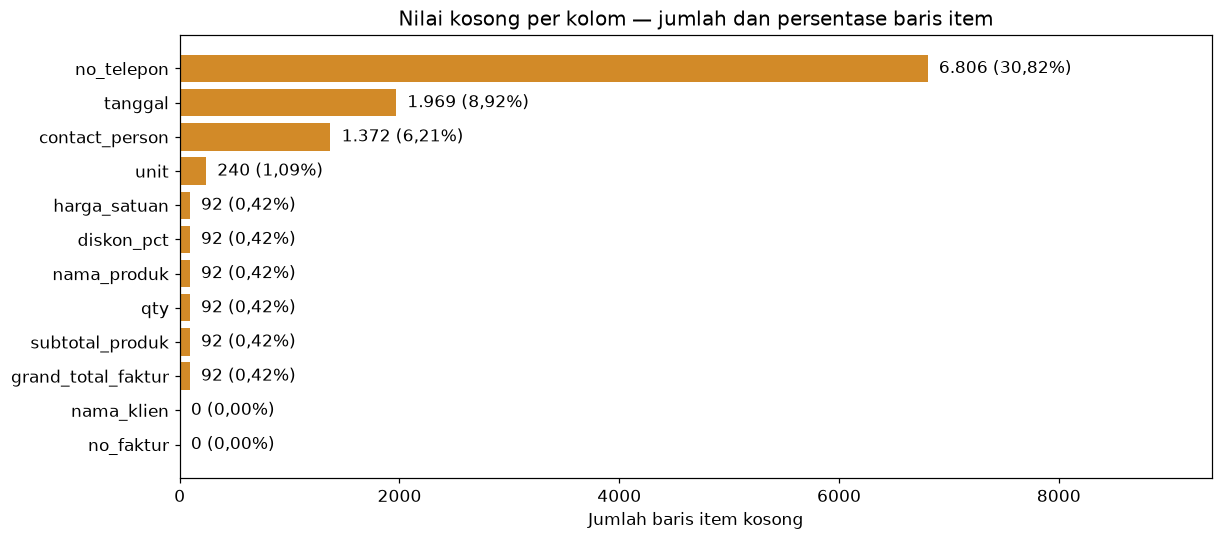

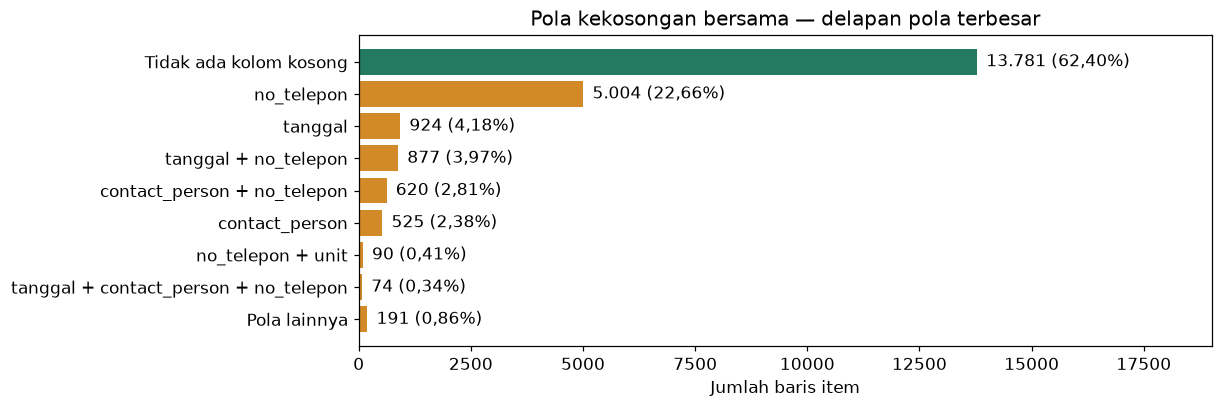

**Interpretasi.** Kolom no_telepon kosong pada 6.806 dari 22.086 baris item (30,82%); pola paling sering adalah **Tidak ada kolom kosong**, sebanyak 13.781 baris (62,40%). Kekosongan atribut dapat membatasi penautan pelanggan dan perhitungan RFM. Pada cleaning, telusuri atribut wajib ke dokumen sumber sebelum mengisi nilai.

In [5]:
from IPython.display import Markdown
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})
GOOD, EMPTY, CONFLICT = '#247a60', '#d28a28', '#bb4545'
N, NI = len(d), len(rows_per_invoice)
def angka(x): return f'{int(x):,}'.replace(',', '.')
def pct(x, den=N): return f'{100*x/den:.2f}%'.replace('.', ',') if den else '0,00%'
def note(s): display(Markdown(s))
def finish(fig):
    display(fig)
    plt.close(fig)
def bars(series, title, xlabel, den=None, color=EMPTY):
    fig, ax = plt.subplots(figsize=(11, max(3.4, len(series)*.40)), layout='constrained')
    ax.barh(range(len(series)), series.values, color=color)
    ax.set_yticks(range(len(series)), series.index.astype(str))
    ax.invert_yaxis()
    ax.set(title=title, xlabel=xlabel)
    limit=max(float(series.max()),1)
    ax.set_xlim(0,limit*1.38)
    for i,v in enumerate(series):
        ax.text(v+limit*.015,i,angka(v)+(f' ({pct(v,den)})' if den is not None else ''),va='center')
    finish(fig)
missing_counts = profile['kosong_termasuk_spasi'].sort_values(ascending=False)
bars(missing_counts, 'Nilai kosong per kolom — jumlah dan persentase baris item', 'Jumlah baris item kosong', N)
missing_mask = d[REQUIRED].apply(blank)
patterns = missing_mask.apply(lambda row: ' + '.join(row.index[row]) or 'Tidak ada kolom kosong', axis=1).value_counts()
# All patterns are retained in an aggregate table; show the largest for legibility.
pattern_plot=patterns.head(8).copy()
if len(patterns)>8: pattern_plot.loc['Pola lainnya']=patterns.iloc[8:].sum()
bars(pattern_plot, 'Pola kekosongan bersama — delapan pola terbesar', 'Jumlah baris item', N, [GOOD if name=='Tidak ada kolom kosong' else EMPTY for name in pattern_plot.index])
worst=missing_counts.index[0]
note(f"**Interpretasi.** Kolom {worst} kosong pada {angka(missing_counts.iloc[0])} dari {angka(N)} baris item ({pct(missing_counts.iloc[0])}); pola paling sering adalah **{patterns.index[0]}**, sebanyak {angka(patterns.iloc[0])} baris ({pct(patterns.iloc[0])}). Kekosongan atribut dapat membatasi penautan pelanggan dan perhitungan RFM. Pada cleaning, telusuri atribut wajib ke dokumen sumber sebelum mengisi nilai.")


## 2. Seberapa sering satu nomor faktur muncul di beberapa baris?
Semua persentase pada kelompok grafik ini memakai nomor faktur unik terisi sebagai penyebut. Konflik menghitung nomor yang memiliki lebih dari satu nilai terisi; kategori konflik bisa tumpang tindih.

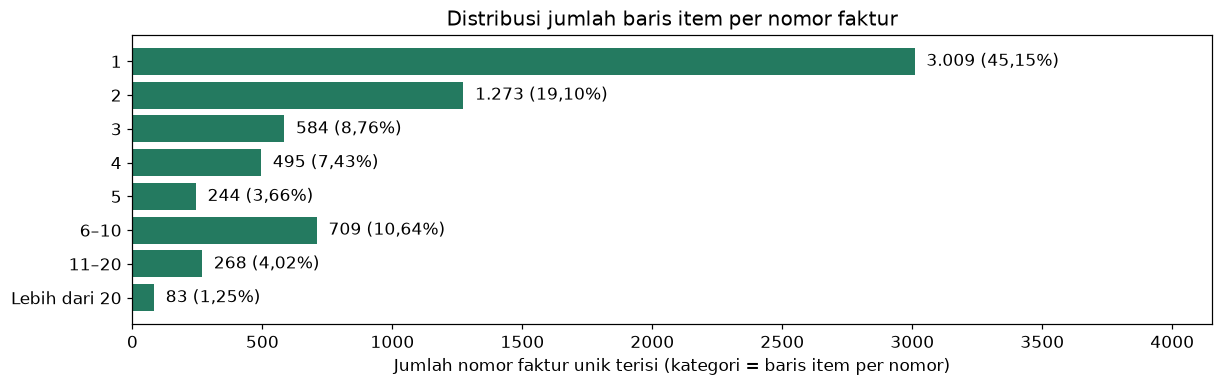

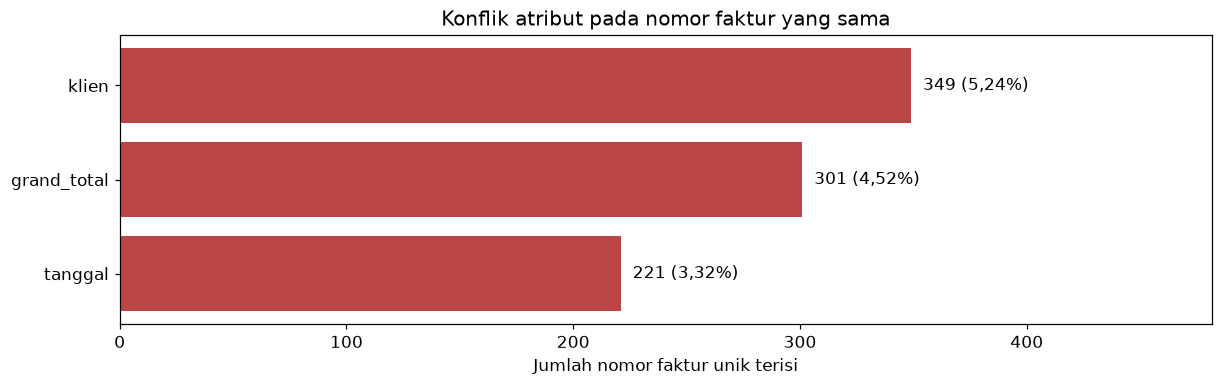

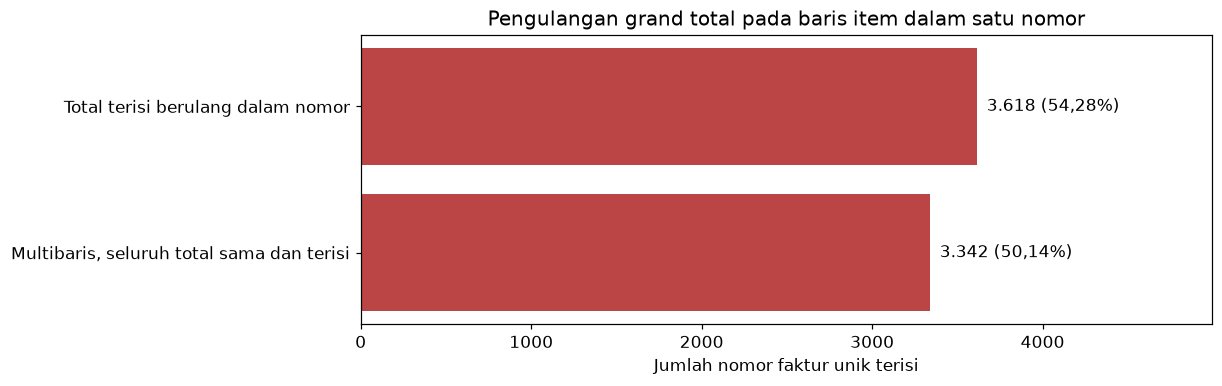

**Interpretasi.** Dari 6.665 nomor unik terisi, 3.656 (54,85%) muncul pada beberapa baris; terdapat 0 baris tanpa nomor. Konflik klien, tanggal, dan total masing-masing mencakup 349, 221, dan 301 nomor (persentase pada grafik), sehingga nomor unik belum dapat dipakai sebagai jumlah faktur untuk Frequency. Total berulang pada 3.618 nomor (54,28%); validasi ID/cabang/seri faktur dan rekonsiliasi total sebelum menghitung Monetary, karena menjumlahkan total setiap item dapat menggandakan nilai.

In [6]:
invoice_bins=pd.cut(rows_per_invoice,bins=[0,1,2,3,4,5,10,20,np.inf],labels=['1','2','3','4','5','6–10','11–20','Lebih dari 20']).value_counts(sort=False)
assert invoice_bins.sum()==NI
bars(invoice_bins, 'Distribusi jumlah baris item per nomor faktur', 'Jumlah nomor faktur unik terisi (kategori = baris item per nomor)', NI, GOOD)
bars(conflict_table['konflik_nilai_terisi'].sort_values(ascending=False), 'Konflik atribut pada nomor faktur yang sama', 'Jumlah nomor faktur unik terisi', NI, CONFLICT)
repeat_series=pd.Series({'Total terisi berulang dalam nomor': repeated_total_numbers,
                        'Multibaris, seluruh total sama dan terisi': same_total_multiline})
bars(repeat_series,'Pengulangan grand total pada baris item dalam satu nomor', 'Jumlah nomor faktur unik terisi', NI, CONFLICT)
note(f"**Interpretasi.** Dari {angka(NI)} nomor unik terisi, {angka(rows_per_invoice.gt(1).sum())} ({pct(rows_per_invoice.gt(1).sum(),NI)}) muncul pada beberapa baris; terdapat {angka(invoice_blank.sum())} baris tanpa nomor. Konflik klien, tanggal, dan total masing-masing mencakup {angka(conflict_table.loc['klien','konflik_nilai_terisi'])}, {angka(conflict_table.loc['tanggal','konflik_nilai_terisi'])}, dan {angka(conflict_table.loc['grand_total','konflik_nilai_terisi'])} nomor (persentase pada grafik), sehingga nomor unik belum dapat dipakai sebagai jumlah faktur untuk Frequency. Total berulang pada {angka(repeated_total_numbers)} nomor ({pct(repeated_total_numbers,NI)}); validasi ID/cabang/seri faktur dan rekonsiliasi total sebelum menghitung Monetary, karena menjumlahkan total setiap item dapat menggandakan nilai.")


## 3. Seberapa lengkap dan terbaca tanggal transaksi?
Grafik bulanan mencakup semua baris dengan tanggal berhasil dibaca, termasuk teks ambigu yang dibaca sementara dengan asumsi hari/bulan/tahun. Tanggal kosong dan gagal dibaca tidak masuk; grafik menghitung baris item, bukan jumlah faktur atau penjualan.

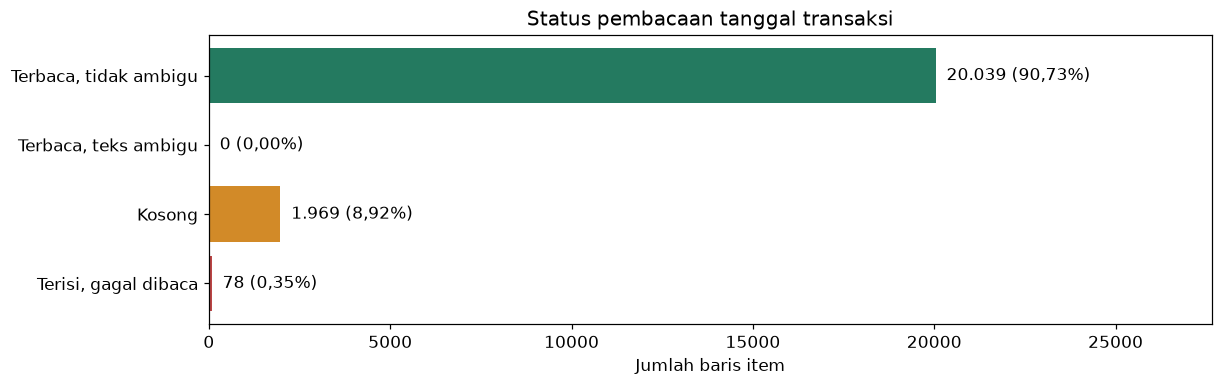

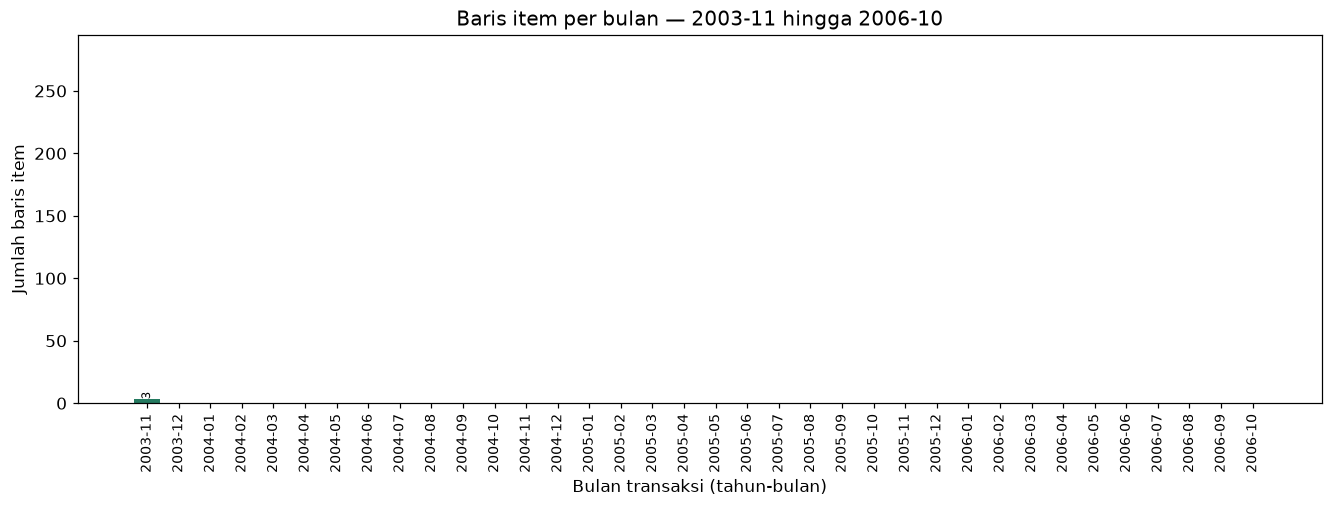

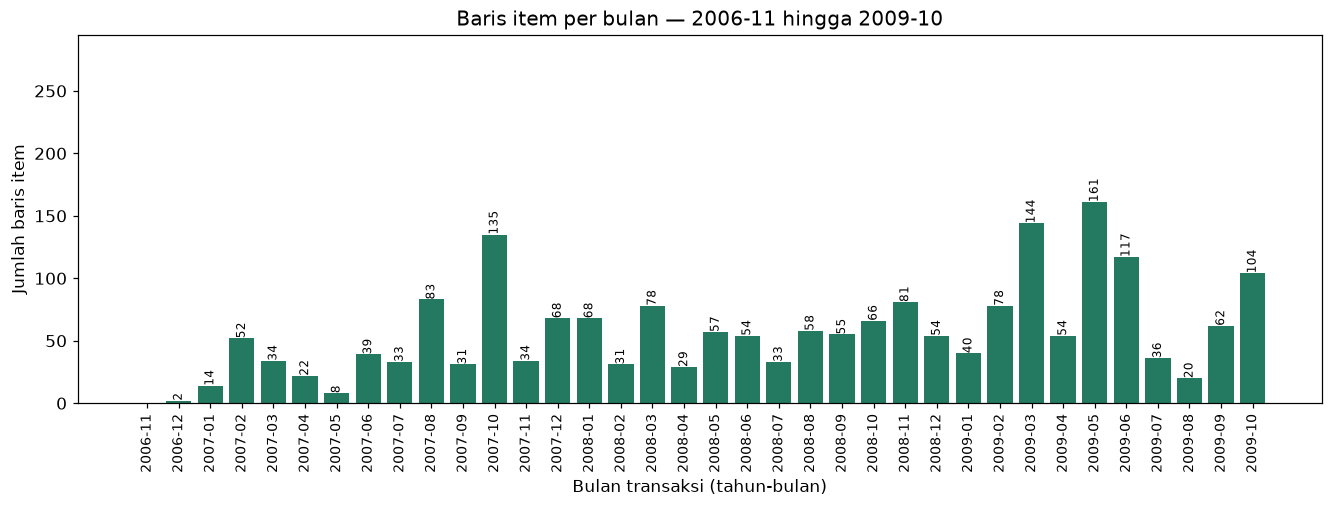

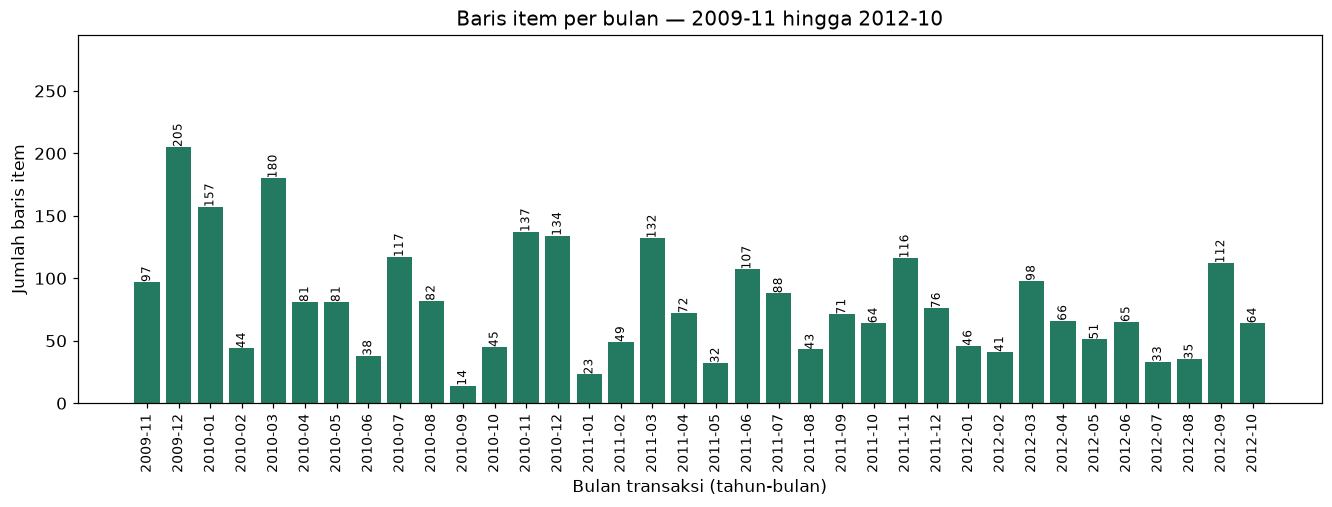

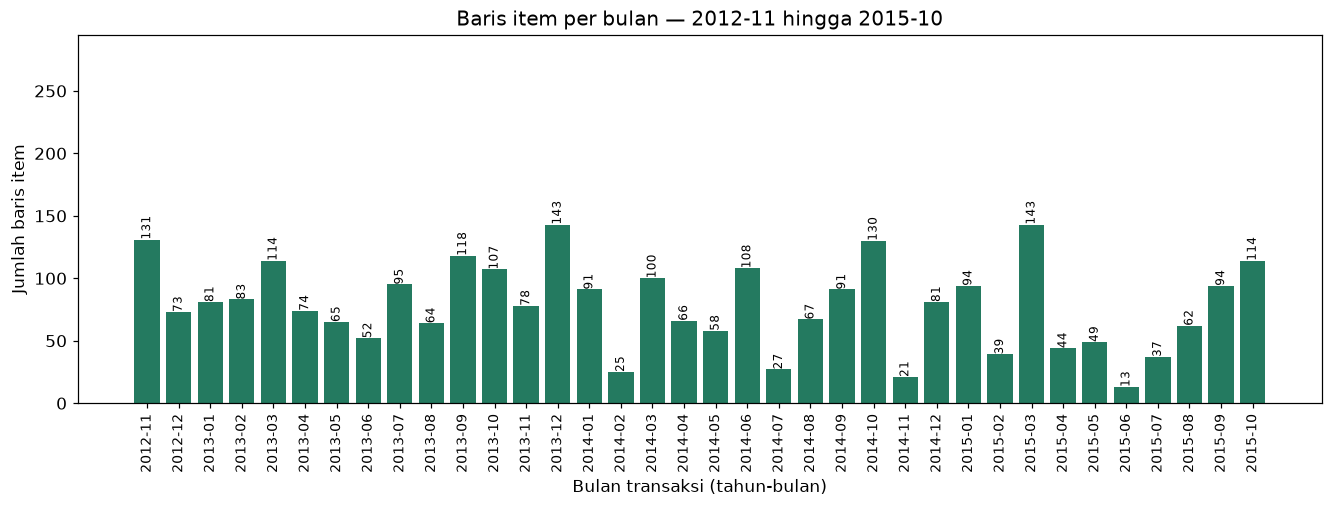

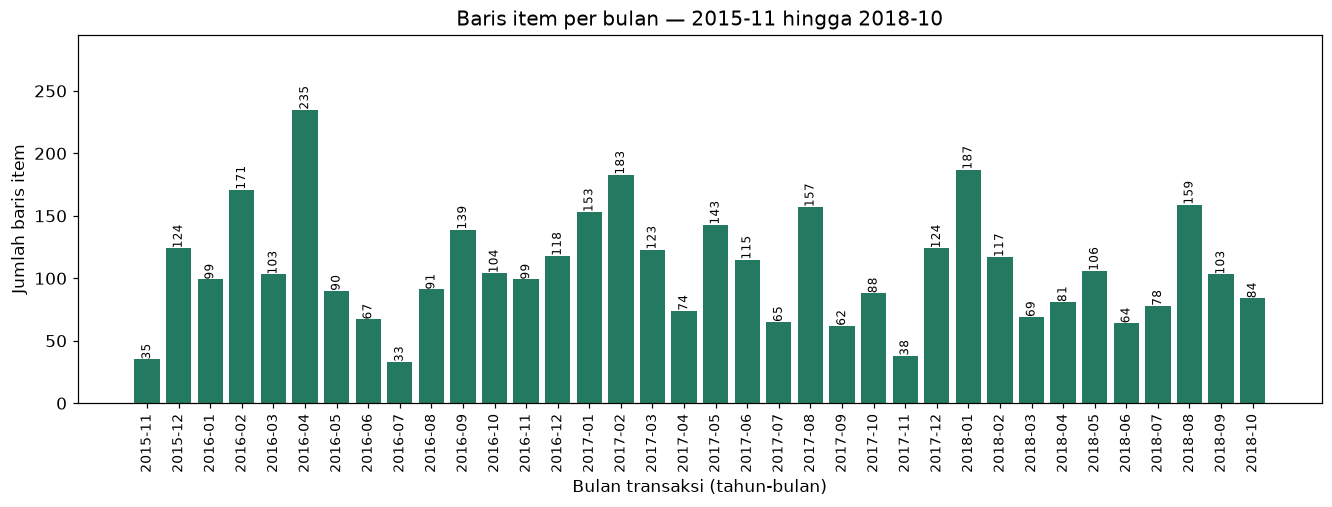

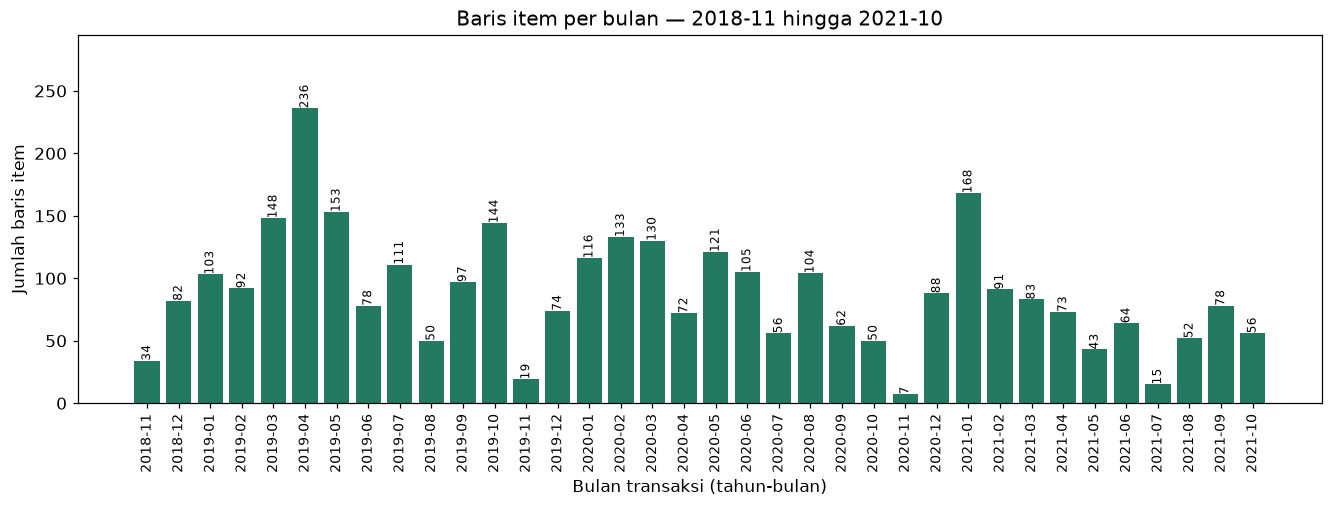

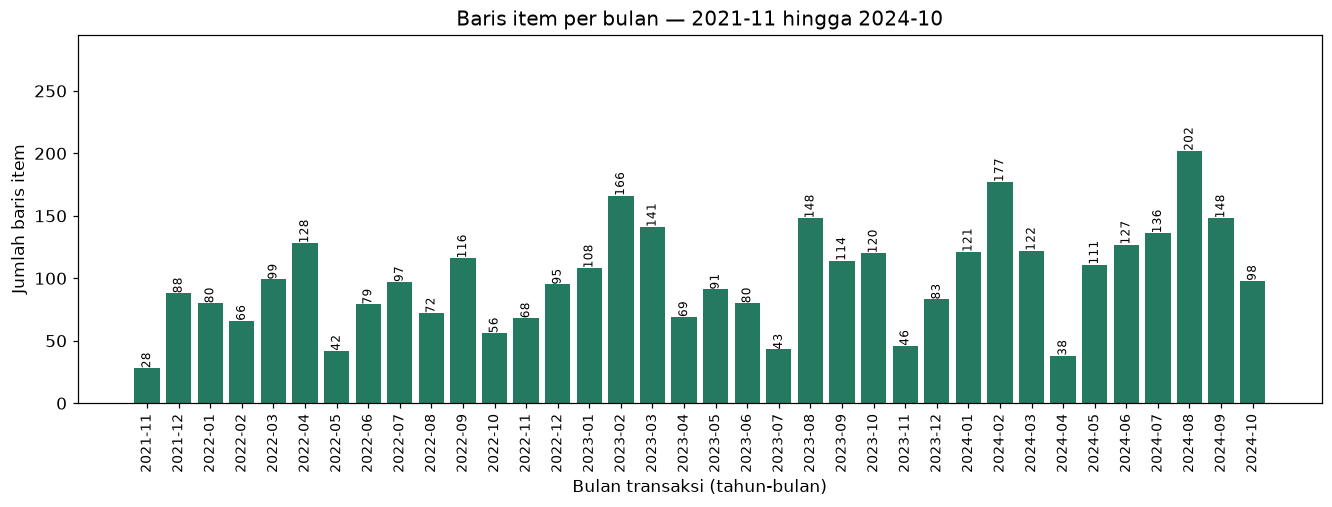

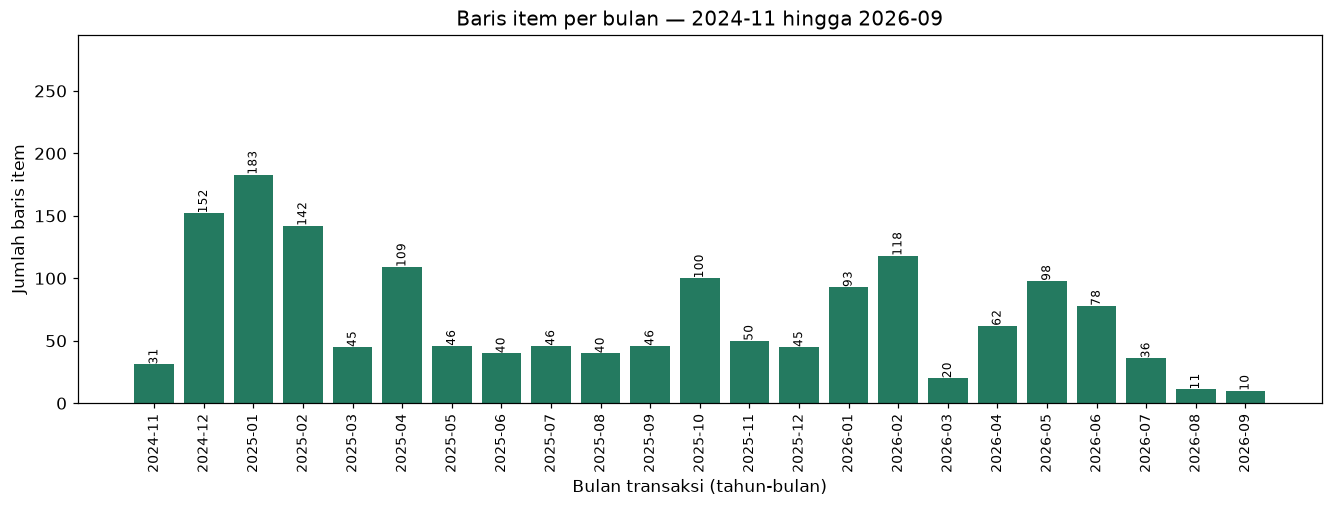

**Interpretasi.** Tanggal kosong pada 1.969 dari 22.086 baris item (8,92%); 78 baris (0,35%) terisi tetapi gagal dibaca. Grafik bulanan memuat 20.039 baris, termasuk 0 tanggal teks ambigu (0,00% dari seluruh baris), rentang bulan terbaca adalah 2003-11 sampai 2026-09, sehingga sebarannya masih bersifat diagnostik dan belum menjadi dasar Recency. Telusuri tanggal kosong/gagal ke faktur sumber dan konfirmasi format day-first sebelum menentukan transaksi terakhir pelanggan.

In [7]:
date_status=pd.Series({'Terbaca, tidak ambigu': int((d['_tanggal'].notna() & ~d['_ambigu']).sum()),
                      'Terbaca, teks ambigu': int((d['_tanggal'].notna() & d['_ambigu']).sum()),
                      'Kosong': int(date_blank.sum()), 'Terisi, gagal dibaca': int(date_failed.sum())})
bars(date_status,'Status pembacaan tanggal transaksi', 'Jumlah baris item', N, [GOOD, EMPTY, EMPTY, CONFLICT])
monthly=d.loc[d['_tanggal'].notna(), '_tanggal'].dt.to_period('M').value_counts().sort_index()
monthly=monthly.reindex(pd.period_range(monthly.index.min(),monthly.index.max(),freq='M'),fill_value=0)
# Panels of 36 consecutive months keep labels readable, including zero months.
for start in range(0,len(monthly),36):
    panel=monthly.iloc[start:start+36]
    fig,ax=plt.subplots(figsize=(12,4.5),layout='constrained')
    ax.bar(range(len(panel)),panel.values,color=GOOD)
    ax.set_xticks(range(len(panel)),panel.index.astype(str),rotation=90,fontsize=9)
    ax.set(title=f'Baris item per bulan — {panel.index[0]} hingga {panel.index[-1]}',xlabel='Bulan transaksi (tahun-bulan)',ylabel='Jumlah baris item')
    for i,v in enumerate(panel):
        if v: ax.text(i,v,angka(v),ha='center',va='bottom',rotation=90,fontsize=8)
    ax.set_ylim(0,max(monthly)*1.25)  # same scale in every panel
    finish(fig)

note(f"**Interpretasi.** Tanggal kosong pada {angka(date_blank.sum())} dari {angka(N)} baris item ({pct(date_blank.sum())}); {angka(date_failed.sum())} baris ({pct(date_failed.sum())}) terisi tetapi gagal dibaca. Grafik bulanan memuat {angka(monthly.sum())} baris, termasuk {angka(d['_ambigu'].sum())} tanggal teks ambigu ({pct(d['_ambigu'].sum())} dari seluruh baris), rentang bulan terbaca adalah {monthly.index[0]} sampai {monthly.index[-1]}, sehingga sebarannya masih bersifat diagnostik dan belum menjadi dasar Recency. Telusuri tanggal kosong/gagal ke faktur sumber dan konfirmasi format day-first sebelum menentukan transaksi terakhir pelanggan.")


## 4. Apakah nilai transaksi sangat jauh dari mayoritas?
Subtotal ditampilkan pada tingkat baris item. Sumbu rupiah memakai **symlog**: jarak dekat nol linear (hingga ±Rp1.000), lalu logaritmik; jarak yang sama pada bagian log menunjukkan kelipatan nilai, bukan selisih rupiah yang sama. Kandidat IQR adalah nilai di bawah Q1 − 1,5 × IQR atau di atas Q3 + 1,5 × IQR; dihitung terpisah untuk setiap kolom dari nilai numerik terisi.

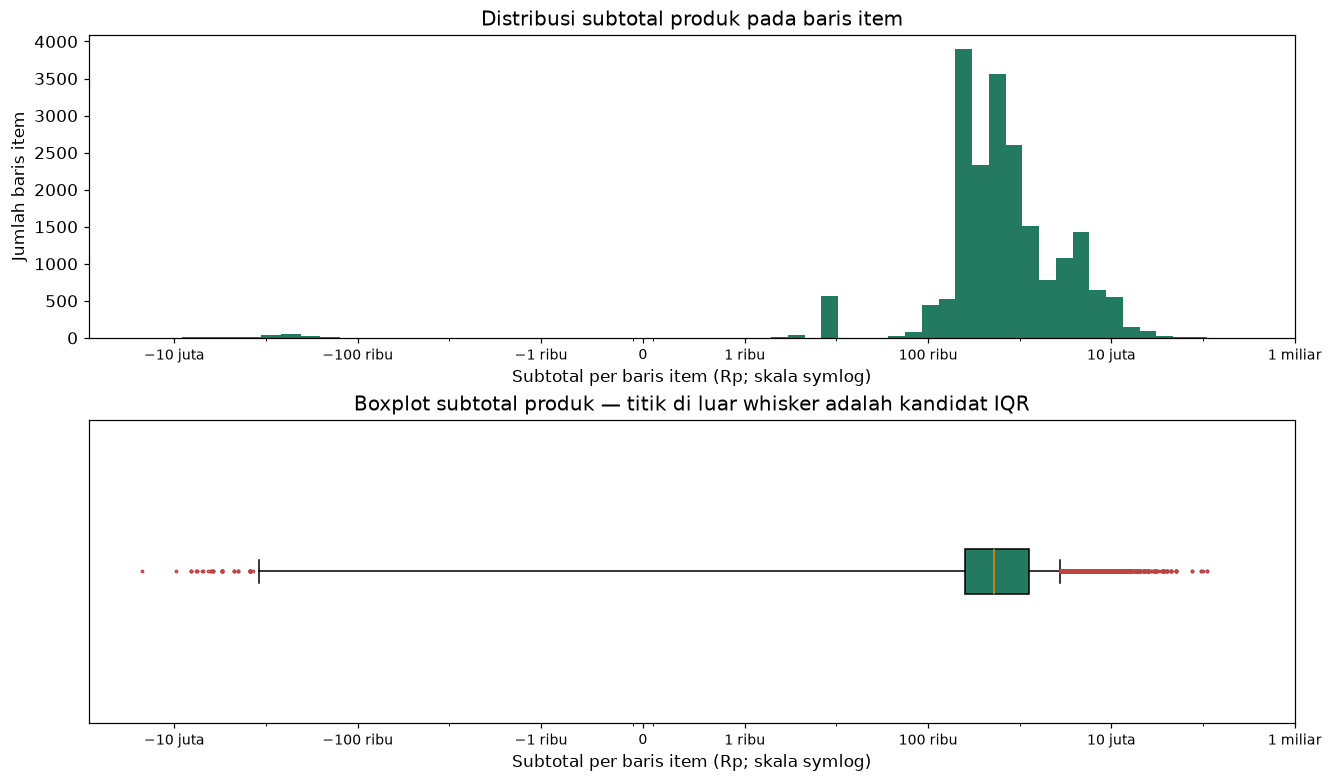

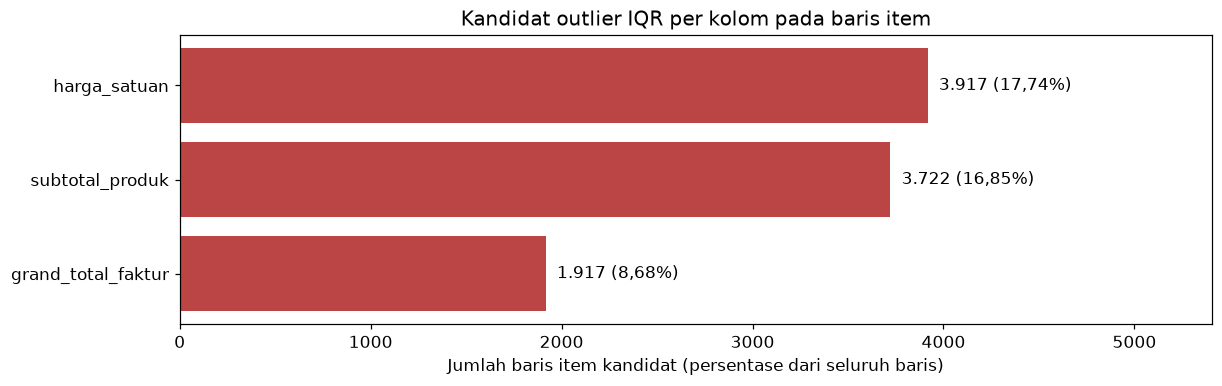

,numerik_terisi,kosong_atau_non_numerik,batas_bawah_Rp,batas_atas_Rp,kandidat_baris,persen_seluruh_baris,persen_numerik_terisi
kolom,,,,,,,
harga_satuan,21994,92,-1375000.0,3225000.0,3917,17.74,17.81
subtotal_produk,21994,92,-1265000.0,2775000.0,3722,16.85,16.92
grand_total_faktur,21994,92,-9639750.0,22183850.0,1917,8.68,8.72


**Interpretasi.** harga_satuan: 3.917 dari 22.086 baris item (17,74%); subtotal_produk: 3.722 dari 22.086 baris item (16,85%); grand_total_faktur: 1.917 dari 22.086 baris item (8,68%) merupakan kandidat IQR; subtotal negatif ditemukan pada 170 baris (0,77%). Nilai ekstrem dapat memengaruhi Monetary, tetapi bisa mencakup transaksi besar atau retur yang sah, dan grand total di sini masih berada pada tingkat baris item. Periksa harga, kuantitas, diskon, retur, serta rekonsiliasi faktur pada cleaning sebelum memutuskan perlakuannya; tidak ada kandidat yang dihapus.

In [8]:
money_cols=['harga_satuan','subtotal_produk','grand_total_faktur']
iqr_rows=[]
for col in money_cols:
    v=pd.to_numeric(d[col],errors='coerce')
    q1,q3=v.quantile([.25,.75]); spread=q3-q1
    low,high=q1-1.5*spread,q3+1.5*spread
    candidates=v.lt(low)|v.gt(high)
    iqr_rows.append({'kolom':col,'numerik_terisi':int(v.notna().sum()),'kosong_atau_non_numerik':int(v.isna().sum()),'batas_bawah_Rp':low,'batas_atas_Rp':high,'kandidat_baris':int(candidates.sum()),'persen_seluruh_baris':100*candidates.sum()/N,'persen_numerik_terisi':100*candidates.sum()/v.notna().sum()})
iqr_table=pd.DataFrame(iqr_rows).set_index('kolom')
fig,axes=plt.subplots(2,1,figsize=(12,7),layout='constrained')
v=subtotal.dropna()
edges=np.unique(np.r_[-np.geomspace(1,max(abs(v.min()),2),35),0,np.geomspace(1,max(v.max(),2),45)])
axes[0].hist(v,bins=edges,color=GOOD)
axes[0].set(title='Distribusi subtotal produk pada baris item',ylabel='Jumlah baris item')
axes[1].boxplot(v,orientation='horizontal',patch_artist=True,boxprops={'facecolor':GOOD},flierprops={'marker':'.','markersize':3,'markeredgecolor':CONFLICT})
axes[1].set(title='Boxplot subtotal produk — titik di luar whisker adalah kandidat IQR',yticks=[])
for ax in axes:
    ax.set_xscale('symlog',linthresh=1000)
    ax.set_xticks([-1e7,-1e5,-1e3,0,1e3,1e5,1e7,1e9])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos: ('−' if x<0 else '') + (f'{abs(x)/1e9:g} miliar' if abs(x)>=1e9 else f'{abs(x)/1e6:g} juta' if abs(x)>=1e6 else f'{abs(x)/1e3:g} ribu' if abs(x)>=1e3 else '0')))
    ax.tick_params(axis='x',labelsize=9)
    ax.set_xlabel('Subtotal per baris item (Rp; skala symlog)')
finish(fig)
bars(iqr_table['kandidat_baris'].sort_values(ascending=False), 'Kandidat outlier IQR per kolom pada baris item', 'Jumlah baris item kandidat (persentase dari seluruh baris)', N, CONFLICT)
display(iqr_table.round(2))
note('**Interpretasi.** '+ '; '.join(f"{col}: {angka(row.kandidat_baris)} dari {angka(N)} baris item ({pct(row.kandidat_baris)})" for col,row in iqr_table.iterrows()) + f" merupakan kandidat IQR; subtotal negatif ditemukan pada {angka(subtotal.lt(0).sum())} baris ({pct(subtotal.lt(0).sum())}). Nilai ekstrem dapat memengaruhi Monetary, tetapi bisa mencakup transaksi besar atau retur yang sah, dan grand total di sini masih berada pada tingkat baris item. Periksa harga, kuantitas, diskon, retur, serta rekonsiliasi faktur pada cleaning sebelum memutuskan perlakuannya; tidak ada kandidat yang dihapus.")


## 5. Apakah nama produk siap untuk menghitung keragaman produk?
Normalisasi diagnostik hanya memangkas spasi tepi, merapatkan spasi berulang, dan menyamakan huruf besar/kecil. Ini mengukur indikasi variasi penulisan, belum membuktikan bahwa produk yang berbeda adalah produk yang sama.

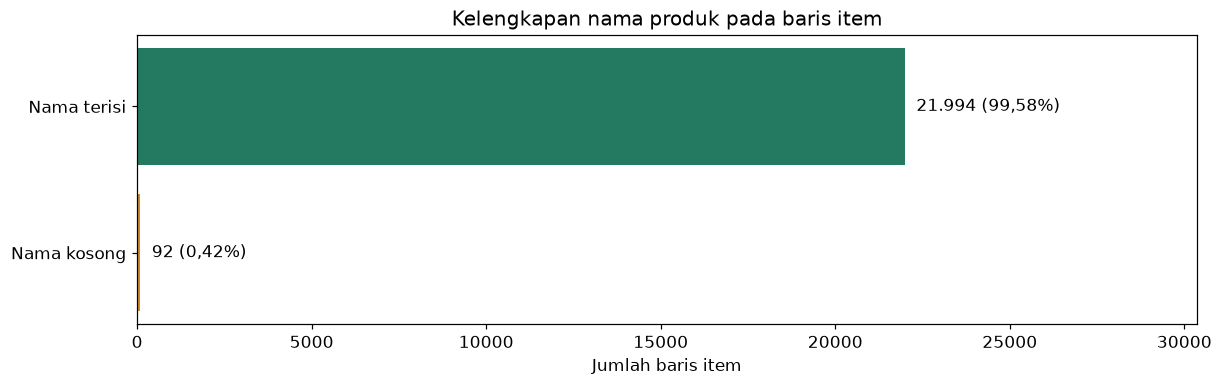

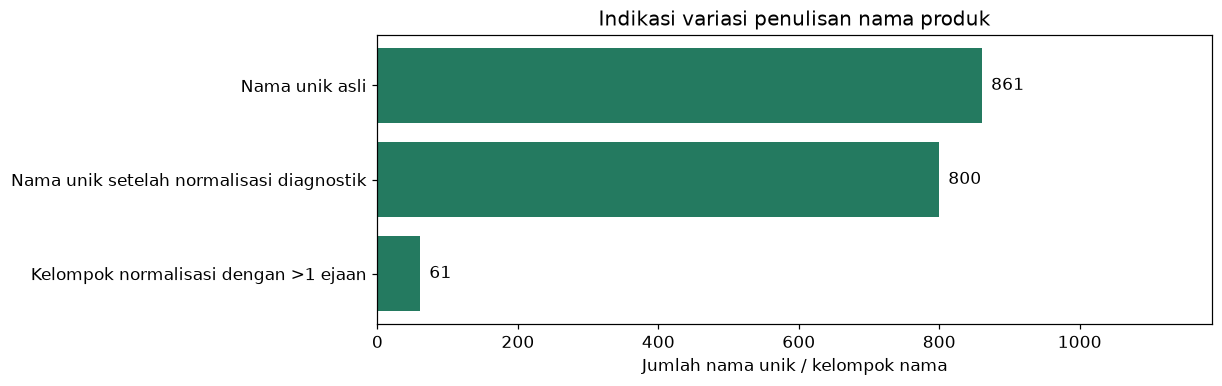

**Interpretasi.** Nama produk kosong pada 92 dari 22.086 baris item (0,42%); 861 nama unik asli menjadi 800 nama setelah normalisasi diagnostik. Ada 61 kelompok dengan variasi penulisan yang mencakup 11.438 baris (51,79% dari seluruh baris), sehingga keragaman produk dapat terhitung berlebih atau tidak lengkap. Validasi kode/katalog produk dan telusuri nama kosong sebelum penggabungan pada cleaning; normalisasi ini tidak mengubah data sumber.

In [9]:
bars(pd.Series({'Nama terisi':int((~product_blank).sum()),'Nama kosong':int(product_blank.sum())}), 'Kelengkapan nama produk pada baris item', 'Jumlah baris item', N, [GOOD,EMPTY])
bars(pd.Series({'Nama unik asli': products.nunique(),'Nama unik setelah normalisasi diagnostik':product_norm.nunique(),'Kelompok normalisasi dengan >1 ejaan':variant_groups}), 'Indikasi variasi penulisan nama produk', 'Jumlah nama unik / kelompok nama', color=GOOD)
note(f"**Interpretasi.** Nama produk kosong pada {angka(product_blank.sum())} dari {angka(N)} baris item ({pct(product_blank.sum())}); {angka(products.nunique())} nama unik asli menjadi {angka(product_norm.nunique())} nama setelah normalisasi diagnostik. Ada {angka(variant_groups)} kelompok dengan variasi penulisan yang mencakup {angka(variant_rows)} baris ({pct(variant_rows)} dari seluruh baris), sehingga keragaman produk dapat terhitung berlebih atau tidak lengkap. Validasi kode/katalog produk dan telusuri nama kosong sebelum penggabungan pada cleaning; normalisasi ini tidak mengubah data sumber.")


## Tabel Audit Akhir
Rujukan angka untuk grafik dan narasi. Kasus dapat tumpang tindih sehingga jumlah antarbaris tidak boleh dijumlahkan. Satuan “baris” berarti baris item; “nomor” berarti nomor unik terisi yang belum divalidasi sebagai faktur.

In [10]:
audit_rows = []
def audit(kind, count, unit, impact, action):
    audit_rows.append({'pemeriksaan': kind, 'jumlah_kasus': int(count), 'unit': unit,
                       'dampak_RFM': impact, 'validasi_Tahap_2': action})
audit('Baris identik tambahan', identical_extra, 'baris', 'Potensi penggelembungan nilai/frekuensi', 'Periksa ID item dan bukti sumber sebelum menghapus')
audit('Anggota kelompok identik', identical_members, 'baris', 'Menunjukkan cakupan duplikasi', 'Bedakan item sah dari duplikasi ekstraksi')
audit('Nomor faktur kosong', invoice_blank.sum(), 'baris', 'Frekuensi tidak dapat ditautkan', 'Telusuri nomor atau ID transaksi sumber')
audit('Nomor multibaris', rows_per_invoice.gt(1).sum(), 'nomor', 'Jumlah baris bukan Frequency', 'Validasi grain item dan aturan agregasi')
for label, row in conflict_table.iterrows():
    audit(f'Konflik {label} antar-nilai terisi', row['konflik_nilai_terisi'], 'nomor', 'Identitas/grain atau nilai RFM tidak pasti', 'Periksa ID transaksi, cabang, seri, dan dokumen sumber')
    audit(f'{label}: nomor dengan nilai kosong', row['nomor_dengan_kosong'], 'nomor', 'Atribut RFM tidak lengkap', 'Validasi sumber; jangan isi otomatis')
audit('Tanggal kosong', date_blank.sum(), 'baris', 'Recency tidak tersedia', 'Konfirmasi tanggal transaksi sumber')
audit('Tanggal gagal parsing', date_failed.sum(), 'baris', 'Recency tidak dapat dihitung', 'Periksa format/serial Excel dan lokal sumber')
audit('Tanggal ambigu', d['_ambigu'].sum(), 'baris', 'Recency mungkin bergeser', 'Konfirmasi lokal day-first dengan pemilik data')
audit('Total berulang dalam nomor', repeated_total_numbers, 'nomor', 'Monetary membesar jika total dijumlahkan', 'Rekonsiliasi total faktur dan subtotal item')
audit('Subtotal negatif', subtotal.lt(0).sum(), 'baris', 'Retur/koreksi memengaruhi Monetary', 'Periksa status retur dan pembatalan')
audit('Nama produk kosong', product_blank.sum(), 'baris', 'Interpretasi komposisi belanja terbatas', 'Telusuri kode produk sumber')
audit('Kelompok variasi nama produk', variant_groups, 'kelompok normalisasi', 'Kategori belanja dapat terpecah', 'Validasi kode produk sebelum penggabungan')
for col,row in iqr_table.iterrows():
    audit(f'Kandidat outlier IQR: {col}', row['kandidat_baris'], 'baris', 'Nilai ekstrem dapat memengaruhi Monetary', 'Periksa dokumen; kandidat dapat berupa transaksi sah')
audit('Baris dalam kelompok variasi produk', variant_rows, 'baris', 'Keragaman dapat terpecah', 'Validasi kode produk')
audit('Multibaris dengan seluruh total sama terisi', same_total_multiline, 'nomor', 'Total dapat terhitung berulang', 'Rekonsiliasi nilai faktur')
audit_table = pd.DataFrame(audit_rows)
audit_table['persen_dari_unit_acuan'] = audit_table.apply(lambda r: 100*r['jumlah_kasus']/(N if r['unit']=='baris' else NI) if r['unit'] in ['baris','nomor'] else np.nan,axis=1)
display(audit_table)
key_conflicts = int(conflict_table['konflik_nilai_terisi'].sum())
if key_conflicts:
    print('no_faktur belum layak ditetapkan sebagai kunci faktur tunggal: terdapat konflik antar-nilai terisi.')
else:
    print('Belum ada konflik antar-nilai terisi yang terdeteksi, tetapi keunikan bisnis no_faktur tetap perlu dikonfirmasi.')
display(pd.DataFrame({'metrik': ['Jumlah baris mentah', 'Jumlah nomor faktur unik terisi', 'Jumlah faktur valid'],
                      'hasil': [str(len(d)), str(len(rows_per_invoice)), 'Belum ditetapkan; menunggu aturan cleaning dan validasi kunci']}))
assert df_raw.equals(raw_snapshot), 'DataFrame mentah berubah selama diagnosis.'
verification_summary = {'baris_mentah': len(d), 'nomor_unik': len(rows_per_invoice),
                        'identik_tambahan': identical_extra, 'identik_anggota': identical_members,
                        'konflik': conflict_table.to_dict('index'), 'tanggal_kosong': int(date_blank.sum()),
                        'tanggal_gagal': int(date_failed.sum()), 'tanggal_ambigu': int(d['_ambigu'].sum()),
                        'nomor_total_berulang': repeated_total_numbers, 'variasi_produk': variant_groups}
print(json.dumps(verification_summary, ensure_ascii=False))


,pemeriksaan,jumlah_kasus,unit,dampak_RFM,validasi_Tahap_2,persen_dari_unit_acuan
0,Baris identik tambahan,2253,baris,Potensi penggelembungan nilai/frekuensi,Periksa ID item dan bukti sumber sebelum mengh...,10.201032
1,Anggota kelompok identik,3936,baris,Menunjukkan cakupan duplikasi,Bedakan item sah dari duplikasi ekstraksi,17.821244
2,Nomor faktur kosong,0,baris,Frekuensi tidak dapat ditautkan,Telusuri nomor atau ID transaksi sumber,0.000000
3,Nomor multibaris,3656,nomor,Jumlah baris bukan Frequency,Validasi grain item dan aturan agregasi,54.853713
4,Konflik klien antar-nilai terisi,349,nomor,Identitas/grain atau nilai RFM tidak pasti,"Periksa ID transaksi, cabang, seri, dan dokume...",5.236309
5,klien: nomor dengan nilai kosong,0,nomor,Atribut RFM tidak lengkap,Validasi sumber; jangan isi otomatis,0.000000
6,Konflik tanggal antar-nilai terisi,221,nomor,Identitas/grain atau nilai RFM tidak pasti,"Periksa ID transaksi, cabang, seri, dan dokume...",3.315829
7,tanggal: nomor dengan nilai kosong,761,nomor,Atribut RFM tidak lengkap,Validasi sumber; jangan isi otomatis,11.417854
8,Konflik grand_total antar-nilai terisi,301,nomor,Identitas/grain atau nilai RFM tidak pasti,"Periksa ID transaksi, cabang, seri, dan dokume...",4.516129
9,grand_total: nomor dengan nilai kosong,27,nomor,Atribut RFM tidak lengkap,Validasi sumber; jangan isi otomatis,0.405101


no_faktur belum layak ditetapkan sebagai kunci faktur tunggal: terdapat konflik antar-nilai terisi.


,metrik,hasil
0,Jumlah baris mentah,22086
1,Jumlah nomor faktur unik terisi,6665
2,Jumlah faktur valid,Belum ditetapkan; menunggu aturan cleaning dan...


{"baris_mentah": 22086, "nomor_unik": 6665, "identik_tambahan": 2253, "identik_anggota": 3936, "konflik": {"klien": {"konflik_nilai_terisi": 349, "nomor_dengan_kosong": 0, "nomor_kosong_dan_terisi": 0, "nomor_dengan_gagal_parsing": 0}, "tanggal": {"konflik_nilai_terisi": 221, "nomor_dengan_kosong": 761, "nomor_kosong_dan_terisi": 73, "nomor_dengan_gagal_parsing": 25}, "grand_total": {"konflik_nilai_terisi": 301, "nomor_dengan_kosong": 27, "nomor_kosong_dan_terisi": 2, "nomor_dengan_gagal_parsing": 0}}, "tanggal_kosong": 1969, "tanggal_gagal": 78, "tanggal_ambigu": 0, "nomor_total_berulang": 3618, "variasi_produk": 61}


## Temuan Utama dan Keputusan Sebelum Cleaning

In [11]:
findings = [
('Nomor faktur belum tervalidasi', f"{angka(NI)} nomor unik; {angka(rows_per_invoice.gt(1).sum())} multibaris ({pct(rows_per_invoice.gt(1).sum(),NI)})", 'Frequency keliru jika menghitung baris atau nomor yang bertabrakan', 'Validasi ID internal, cabang, seri, klien dan tanggal sebelum menetapkan jumlah faktur'),
('Grand total berulang', f"{angka(repeated_total_numbers)} dari {angka(NI)} nomor ({pct(repeated_total_numbers,NI)})", 'Monetary membesar jika total dijumlahkan pada setiap item', 'Rekonsiliasi subtotal item dengan satu nilai faktur yang tervalidasi'),
('Tanggal perlu konfirmasi', f"Kosong {angka(date_blank.sum())} ({pct(date_blank.sum())}); gagal {angka(date_failed.sum())} ({pct(date_failed.sum())}); ambigu {angka(d['_ambigu'].sum())} ({pct(d['_ambigu'].sum())}), dari {angka(N)} baris", 'Recency dan sebaran waktu dapat berubah', 'Telusuri sumber dan konfirmasi format tanggal'),
('Kandidat nilai ekstrem', '; '.join(f"{col}: {angka(row.kandidat_baris)} ({pct(row.kandidat_baris)})" for col,row in iqr_table.iterrows())+f' dari {angka(N)} baris', 'Nilai ekstrem memengaruhi Monetary; IQR dapat mencakup transaksi sah', 'Periksa harga, diskon, retur dan dokumen; jangan hapus otomatis'),
('Keragaman produk belum final', f"{angka(product_blank.sum())} nama kosong ({pct(product_blank.sum())} dari {angka(N)} baris); {angka(variant_groups)} kelompok variasi", 'Produk yang sama bisa terhitung berbeda', 'Validasi katalog/kode produk sebelum menyatukan nama')]
display(pd.DataFrame(findings,columns=['temuan','bukti_angka','risiko','tindakan_validasi']))
note('**Keputusan:** jumlah nomor faktur unik masih perlu divalidasi sebelum dipakai sebagai jumlah faktur. Cleaning, RFM, dan GMM dikerjakan pada tahap selanjutnya; tidak ada baris dihapus atau nilai sumber diubah pada EDA ini.')
# Cross-check graphic inputs and narrative metrics against the final audit.
lookup=audit_table.set_index('pemeriksaan')['jumlah_kasus']
assert missing_counts.equals(d[REQUIRED].apply(lambda s: blank(s).sum()).sort_values(ascending=False))
assert patterns.sum()==N and date_status.sum()==N
assert row_distribution['jumlah_nomor'].sum()==NI
assert sum(row_distribution.index*row_distribution['jumlah_nomor'])==N-invoice_blank.sum()
assert monthly.sum()==d['_tanggal'].notna().sum()
assert lookup['Tanggal kosong']==date_status['Kosong']
assert lookup['Total berulang dalam nomor']==repeat_series.iloc[0]
assert lookup['Nama produk kosong']==product_blank.sum()
for col,row in iqr_table.iterrows(): assert lookup[f'Kandidat outlier IQR: {col}']==row.kandidat_baris
for label,row in conflict_table.iterrows(): assert lookup[f'Konflik {label} antar-nilai terisi']==row.konflik_nilai_terisi
assert df_raw.equals(raw_snapshot)
print('LULUS: angka grafik/narasi sesuai audit; data mentah tetap utuh.')


,temuan,bukti_angka,risiko,tindakan_validasi
0,Nomor faktur belum tervalidasi,"6.665 nomor unik; 3.656 multibaris (54,85%)",Frequency keliru jika menghitung baris atau no...,"Validasi ID internal, cabang, seri, klien dan ..."
1,Grand total berulang,"3.618 dari 6.665 nomor (54,28%)",Monetary membesar jika total dijumlahkan pada ...,Rekonsiliasi subtotal item dengan satu nilai f...
2,Tanggal perlu konfirmasi,"Kosong 1.969 (8,92%); gagal 78 (0,35%); ambigu...",Recency dan sebaran waktu dapat berubah,Telusuri sumber dan konfirmasi format tanggal
3,Kandidat nilai ekstrem,"harga_satuan: 3.917 (17,74%); subtotal_produk:...",Nilai ekstrem memengaruhi Monetary; IQR dapat ...,"Periksa harga, diskon, retur dan dokumen; jang..."
4,Keragaman produk belum final,"92 nama kosong (0,42% dari 22.086 baris); 61 k...",Produk yang sama bisa terhitung berbeda,Validasi katalog/kode produk sebelum menyatuka...


**Keputusan:** jumlah nomor faktur unik masih perlu divalidasi sebelum dipakai sebagai jumlah faktur. Cleaning, RFM, dan GMM dikerjakan pada tahap selanjutnya; tidak ada baris dihapus atau nilai sumber diubah pada EDA ini.

LULUS: angka grafik/narasi sesuai audit; data mentah tetap utuh.

# Tahap 2 — Cleaning dan Rekonstruksi Faktur
Tahap ini mempertahankan Tahap 1 dan membaca ulang workbook. **Lolos berarti lolos pemeriksaan konsistensi internal workbook, bukan faktur atau identitas pelanggan yang telah disahkan oleh pemilik data.** Tidak ada kunci komposit ditetapkan sebagai kunci final, tidak ada baris dihapus, dan belum ada RFM/GMM.

## 2.1 Bukti identitas dan kandidat kunci
Nomor faktur asli dipakai sebagai kelompok kandidat pemeriksaan, tanpa memangkas atau menyatukan nomor. Kandidat `(nomor, nama klien)` dan `(nomor, nama klien, tanggal)` hanya dievaluasi untuk melihat pemecahan kelompok; pemecahan tidak menyelesaikan konflik atau membuktikan identitas faktur. Nama klien yang sama belum membuktikan pelanggan yang sama; telepon/contact person bukan ID stabil.


In [12]:
import hashlib
source_hash_t2 = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
with pd.ExcelFile(SOURCE, engine='openpyxl') as wb_t2:
    raw_t2 = pd.read_excel(wb_t2, sheet_name=SHEET)
assert raw_t2.equals(df_raw), 'Workbook berbeda dari input Tahap 1; periksa sebelum melanjutkan.'
item_audit = raw_t2.copy(deep=True)
item_audit['source_sheet'] = SHEET
item_audit['source_excel_row'] = np.arange(2, len(raw_t2)+2)
item_audit['source_workbook_sha256'] = source_hash_t2
schema_t2 = pd.DataFrame({'kolom_tersedia': raw_t2.columns, 'tipe': raw_t2.dtypes.astype(str).values})
display(schema_t2)
identity_availability = pd.DataFrame([
    ['ID faktur internal', 'Tidak tersedia'], ['ID pelanggan', 'Tidak tersedia'],
    ['Cabang/perusahaan', 'Tidak tersedia'], ['Seri faktur terpisah', 'Tidak tersedia'],
    ['Nomor faktur', 'Tersedia; konflik ditemukan pada Tahap 1'],
    ['Nama klien', 'Tersedia; atribut nama, bukan ID pelanggan'],
    ['Pajak, ongkir, biaya lain, status retur, ID item', 'Tidak tersedia sebagai kolom terpisah']
],columns=['bukti','ketersediaan'])
display(identity_availability)
# Conservative standardization: originals remain unchanged.
def std_text(s):
    return s.astype('string').mask(blank(s)).str.strip().str.replace(r'\s+', ' ', regex=True).str.casefold()
for col in ['nama_klien','nama_produk','contact_person','no_telepon']:
    item_audit[col+'_std'] = std_text(raw_t2[col])
parsed_t2 = raw_t2['tanggal'].map(parse_diagnostic)
item_audit['tanggal_std'] = pd.to_datetime(parsed_t2.map(lambda x: x[0]))
item_audit['tanggal_format'] = parsed_t2.map(lambda x: x[1])
item_audit['tanggal_ambigu'] = parsed_t2.map(lambda x: x[2])
item_audit['tanggal_dipulihkan'] = False
numeric_cols_t2 = ['qty','harga_satuan','diskon_pct','subtotal_produk','grand_total_faktur']
for col in numeric_cols_t2:
    # Do not guess locale separators or reinterpret date-like quantities.
    s=raw_t2[col]
    normalized=s.map(lambda x: x.strip() if isinstance(x,str) else x)
    safe=normalized.map(lambda x: not isinstance(x,(datetime,date,pd.Timestamp,bool)))
    item_audit[col+'_std']=pd.to_numeric(normalized.where(safe),errors='coerce').astype(float)
item_audit['kelompok_kandidat'] = pd.Series(pd.NA,index=item_audit.index,dtype='Int64')
filled_no=~blank(raw_t2['no_faktur'])
item_audit.loc[filled_no,'kelompok_kandidat']=raw_t2.loc[filled_no].groupby('no_faktur',sort=False).ngroup().astype('Int64')
x=item_audit.loc[filled_no]
candidate_table=pd.DataFrame([
 ['Nomor asli',x['no_faktur'].nunique(), 'Kelompok audit; belum kunci final'],
 ['Nomor + klien asli',x[['no_faktur','nama_klien']].drop_duplicates().shape[0], 'Dapat memecah konflik klien; belum bukti faktur berbeda'],
 ['Nomor + klien asli + tanggal terbaca',x[['no_faktur','nama_klien','tanggal_std']].drop_duplicates().shape[0], 'Dapat memecah konflik tanggal; NaT tetap kategori belum pasti']
],columns=['kandidat','jumlah_kelompok_teramati','keputusan'])
display(candidate_table)
client_links=x.groupby('nama_klien_std').agg(varian_nama=('nama_klien','nunique'),telepon_terisi=('no_telepon_std','nunique'))
phone_links=x.dropna(subset=['no_telepon_std']).groupby('no_telepon_std')['nama_klien_std'].nunique()
display(pd.DataFrame({'pemeriksaan_identitas_pelanggan':['Nama standar dengan >1 ejaan asli','Nama standar dengan >1 telepon terisi','Telepon standar terkait >1 nama standar'],
'jumlah_kelompok':[int(client_links.varian_nama.gt(1).sum()),int(client_links.telepon_terisi.gt(1).sum()),int(phone_links.gt(1).sum())]}))
note('**Batas validasi:** ID internal, ID pelanggan, cabang dan seri tidak tersedia. Karena identitas faktur belum dapat dipastikan secara independen, tidak ada tanggal kosong yang dipulihkan dari baris lain; tanggal hasil parsing hanya kolom turunan, bukan koreksi nilai sumber. Nama dan kontak standar hanya membantu audit dan tidak dipakai untuk menggabungkan pelanggan.')


,kolom_tersedia,tipe
0,no_faktur,object
1,tanggal,object
2,nama_klien,str
3,contact_person,object
4,no_telepon,object
5,nama_produk,str
6,qty,object
7,unit,str
8,harga_satuan,float64
9,diskon_pct,object


,bukti,ketersediaan
0,ID faktur internal,Tidak tersedia
1,ID pelanggan,Tidak tersedia
2,Cabang/perusahaan,Tidak tersedia
3,Seri faktur terpisah,Tidak tersedia
4,Nomor faktur,Tersedia; konflik ditemukan pada Tahap 1
5,Nama klien,"Tersedia; atribut nama, bukan ID pelanggan"
6,"Pajak, ongkir, biaya lain, status retur, ID item",Tidak tersedia sebagai kolom terpisah


,kandidat,jumlah_kelompok_teramati,keputusan
0,Nomor asli,6665,Kelompok audit; belum kunci final
1,Nomor + klien asli,7129,Dapat memecah konflik klien; belum bukti faktu...
2,Nomor + klien asli + tanggal terbaca,7217,Dapat memecah konflik tanggal; NaT tetap kateg...


,pemeriksaan_identitas_pelanggan,jumlah_kelompok
0,Nama standar dengan >1 ejaan asli,110
1,Nama standar dengan >1 telepon terisi,294
2,Telepon standar terkait >1 nama standar,201


**Batas validasi:** ID internal, ID pelanggan, cabang dan seri tidak tersedia. Karena identitas faktur belum dapat dipastikan secara independen, tidak ada tanggal kosong yang dipulihkan dari baris lain; tanggal hasil parsing hanya kolom turunan, bukan koreksi nilai sumber. Nama dan kontak standar hanya membantu audit dan tidak dipakai untuk menggabungkan pelanggan.

## 2.2 Alasan pemeriksaan dan aturan kelulusan
**Menahan seluruh kelompok kandidat:** nomor kosong, konflik klien/tanggal/grand total terisi pada nilai asli, tabrakan setelah pemangkasan nomor, tanggal kosong/gagal/ambigu, klien atau produk kosong, numerik kosong/gagal/non-finite, diskon di luar 0–100, serta selisih total terhadap subtotal melebihi **Rp0,01** (ditambah epsilon komputasi Rp0,000001). Toleransi ini hanya toleransi teknis sen, bukan keputusan materialitas bisnis. Tanggal di masa depan juga ditahan relatif terhadap tanggal eksekusi di Asia/Jakarta.

**Penanda pemeriksaan yang tidak otomatis menggagalkan:** seluruh anggota baris identik, subtotal/kuantitas/harga/total negatif, kandidat IQR, serta perbedaan subtotal terhadap `qty × harga × (1 − diskon/100)`. Baris tersebut tidak dihapus; walaupun konsisten secara internal, penerimaan bisnisnya tetap perlu konfirmasi. Missing unit/kontak dan variasi nama juga dicatat. Status akhir membedakan kelompok lolos tanpa penanda, lolos dengan penanda, dan ditahan; semua tetap memiliki jejak baris sumber.


In [13]:
flags_t2={}
blocking_t2=set()
def flag_t2(reason, mask, blocks=False):
    flags_t2[reason]=pd.Series(mask,index=item_audit.index).fillna(False).astype(bool)
    if blocks: blocking_t2.add(reason)
flag_t2('nomor_faktur_kosong',~filled_no,True)
for label,col in [('klien','nama_klien'),('tanggal','tanggal_std'),('grand_total','grand_total_faktur')]:
    values=item_audit[col].mask(blank(raw_t2['tanggal' if label=='tanggal' else col]))
    counts=values.loc[filled_no].groupby(raw_t2.loc[filled_no,'no_faktur']).nunique()
    bad=counts[counts.gt(1)].index
    flag_t2('konflik_'+label+'_antar_nilai_terisi',raw_t2['no_faktur'].isin(bad),True)
trim_no=raw_t2['no_faktur'].astype('string').str.strip().mask(~filled_no)
trim_counts=pd.DataFrame({'trim':trim_no,'asli':raw_t2['no_faktur']}).dropna(subset=['trim']).groupby('trim')['asli'].nunique()
flag_t2('tabrakan_nomor_setelah_trim',trim_no.isin(trim_counts[trim_counts.gt(1)].index),True)
flag_t2('tanggal_kosong',blank(raw_t2['tanggal']),True)
flag_t2('tanggal_gagal_baca',~blank(raw_t2['tanggal']) & item_audit['tanggal_std'].isna(),True)
flag_t2('tanggal_teks_ambigu',item_audit['tanggal_ambigu'],True)
asof_t2=pd.Timestamp.now(tz='Asia/Jakarta').tz_localize(None).normalize()
flag_t2('tanggal_di_masa_depan',item_audit['tanggal_std'].gt(asof_t2),True)
for col in ['nama_klien','nama_produk']:
    flag_t2(col+'_kosong',blank(raw_t2[col]),True)
for col in numeric_cols_t2:
    flag_t2(col+'_kosong',blank(raw_t2[col]),True)
    flag_t2(col+'_gagal_atau_nonfinite',~blank(raw_t2[col]) & ~np.isfinite(item_audit[col+'_std']),True)
flag_t2('diskon_di_luar_0_100',item_audit['diskon_pct_std'].lt(0)|item_audit['diskon_pct_std'].gt(100),True)
flag_t2('anggota_baris_identik',raw_t2.duplicated(keep=False))
for col in ['qty','harga_satuan','subtotal_produk','grand_total_faktur']:
    flag_t2(col+'_negatif',item_audit[col+'_std'].lt(0))
for col in money_cols:
    v=item_audit[col+'_std']; q1,q3=v[np.isfinite(v)].quantile([.25,.75]); spread=q3-q1
    flag_t2('kandidat_IQR_'+col,v.lt(q1-1.5*spread)|v.gt(q3+1.5*spread))
for col in ['unit','contact_person','no_telepon']:
    flag_t2(col+'_kosong',blank(raw_t2[col]))
item_audit['subtotal_formula_diagnostik']=item_audit['qty_std']*item_audit['harga_satuan_std']*(1-item_audit['diskon_pct_std']/100)
item_audit['selisih_subtotal_formula']=item_audit['subtotal_produk_std']-item_audit['subtotal_formula_diagnostik']
TOL_RP_T2=0.01
EPS_T2=0.000001
flag_t2('subtotal_berbeda_formula_diskon',item_audit['selisih_subtotal_formula'].abs().gt(TOL_RP_T2+EPS_T2))
for col in ['nama_klien','nama_produk']:
    std=item_audit[col+'_std']
    vc=item_audit.groupby(col+'_std')[col].nunique()
    flag_t2('variasi_penulisan_'+col,std.isin(vc[vc.gt(1)].index))
# Build reconstruction diagnostics without selecting a total from conflicting groups.
g2=item_audit.loc[filled_no].groupby('kelompok_kandidat',sort=False)
rekonstruksi_kandidat=g2.agg(jumlah_item=('source_excel_row','size'),
    jumlah_total_unik=('grand_total_faktur_std','nunique'),
    jumlah_total_terisi=('grand_total_faktur_std','count'),
    jumlah_subtotal_terisi=('subtotal_produk_std','count'),
    subtotal_item_Rp=('subtotal_produk_std',lambda s:s.sum(min_count=1)),
    tanggal_unik=('tanggal_std','nunique'))
unique_total=g2['grand_total_faktur_std'].agg(lambda s:s.dropna().iloc[0] if s.nunique()==1 else np.nan)
rekonstruksi_kandidat['grand_total_konsisten_Rp']=unique_total.where(rekonstruksi_kandidat['jumlah_total_terisi'].eq(rekonstruksi_kandidat['jumlah_item']))
# A numeric-consistent total is still withheld when the original values conflict.
raw_conflict_groups=set(item_audit.loc[flags_t2['konflik_grand_total_antar_nilai_terisi'],'kelompok_kandidat'].dropna())
rekonstruksi_kandidat.loc[rekonstruksi_kandidat.index.isin(raw_conflict_groups),'grand_total_konsisten_Rp']=np.nan
rekonstruksi_kandidat['selisih_total_Rp']=rekonstruksi_kandidat['grand_total_konsisten_Rp']-rekonstruksi_kandidat['subtotal_item_Rp']
complete_sub=rekonstruksi_kandidat['jumlah_subtotal_terisi'].eq(rekonstruksi_kandidat['jumlah_item'])
rekonstruksi_kandidat['dapat_direkonsiliasi']=complete_sub & rekonstruksi_kandidat['grand_total_konsisten_Rp'].notna()
rekonstruksi_kandidat['sesuai_total']=rekonstruksi_kandidat['dapat_direkonsiliasi'] & rekonstruksi_kandidat['selisih_total_Rp'].abs().le(TOL_RP_T2+EPS_T2)
flag_t2('selisih_grand_total_dan_subtotal',item_audit['kelompok_kandidat'].isin(rekonstruksi_kandidat.index[rekonstruksi_kandidat['dapat_direkonsiliasi'] & ~rekonstruksi_kandidat['sesuai_total']]),True)
flag_t2('total_tidak_dapat_direkonsiliasi',item_audit['kelompok_kandidat'].isin(rekonstruksi_kandidat.index[~rekonstruksi_kandidat['dapat_direkonsiliasi']]),True)
flag_matrix_t2=pd.DataFrame(flags_t2)
local_block=flag_matrix_t2[sorted(blocking_t2)].any(axis=1)
blocked_groups=set(item_audit.loc[local_block,'kelompok_kandidat'].dropna())
item_audit['ditahan']=local_block|item_audit['kelompok_kandidat'].isin(blocked_groups)
item_audit['alasan_langsung']=flag_matrix_t2.apply(lambda r:tuple(r.index[r]),axis=1)
group_reasons=item_audit.loc[filled_no].groupby('kelompok_kandidat')['alasan_langsung'].agg(lambda seq:tuple(sorted({a for reasons in seq for a in reasons})))
item_audit['alasan_kelompok']=item_audit['kelompok_kandidat'].map(group_reasons)
item_audit['alasan_kelompok']=item_audit.apply(lambda r:r['alasan_langsung'] if pd.isna(r['kelompok_kandidat']) else r['alasan_kelompok'],axis=1)
has_note=item_audit['alasan_kelompok'].map(bool)
item_audit['status_akhir']=np.select([item_audit['ditahan'],has_note],['ditahan_untuk_tinjau','lolos_internal_dengan_penanda'],default='lolos_internal_tanpa_penanda')


## 2.3 Tiga tabel hasil dan rekonsiliasi
`item_lolos`, `faktur_lolos`, dan `kasus_tinjau` dibentuk di memori. Untuk menjaga kerahasiaan, notebook hanya menampilkan ukuran, skema, dan ringkasan agregatnya, tanpa contoh baris pelanggan. `kasus_tinjau` memakai satu baris sumber per alasan: dapat memuat penanda pada item yang lolos maupun penahanan, sehingga jumlah entri bukan jumlah item unik. `item_audit` mencakup seluruh baris sumber dan status akhirnya.

Satu baris `faktur_lolos` adalah satu **kelompok kandidat lolos internal**; ID kelompok hanya referensi teknis dalam workbook ini. Satu grand total dipakai sekali, tidak dijumlahkan per item. Referensi baris sumber tetap disimpan. Selisih tidak ditambahkan sebagai pajak/ongkir: kolom bukti keduanya tidak tersedia. Diskon dan formula item diperiksa sebagai indikasi; item berulang, retur/koreksi, pembulatan, biaya tambahan, atau item tidak lengkap hanya kemungkinan yang memerlukan dokumen sumber, bukan penjelasan yang sudah terbukti.


In [14]:
item_lolos=item_audit.loc[~item_audit['ditahan']].copy()
lolos_groups=item_lolos['kelompok_kandidat'].dropna().unique()
faktur_lolos=rekonstruksi_kandidat.loc[rekonstruksi_kandidat.index.isin(lolos_groups)].copy()
passed_g=item_lolos.groupby('kelompok_kandidat',sort=False)
faktur_lolos['no_faktur_asli']=passed_g['no_faktur'].first()
faktur_lolos['nama_klien_std']=passed_g['nama_klien_std'].first()
faktur_lolos['tanggal_std']=passed_g['tanggal_std'].first()
faktur_lolos['source_excel_rows']=passed_g['source_excel_row'].agg(tuple)
faktur_lolos['alasan_pemeriksaan']=group_reasons.reindex(faktur_lolos.index)
faktur_lolos['status_akhir']=passed_g['status_akhir'].first()
faktur_lolos['batas_validasi']='Konsistensi internal workbook; identitas bisnis belum dikonfirmasi'
review_records=[]
for idx,row in item_audit.iterrows():
    reasons=set(row['alasan_langsung'])
    inherited={r for r in row['alasan_kelompok'] if r in blocking_t2}
    for reason in sorted(reasons|inherited):
        review_records.append({'source_excel_row':row['source_excel_row'], 'kelompok_kandidat':row['kelompok_kandidat'],
            'alasan':reason,'sifat':'menahan_kelompok' if reason in blocking_t2 else 'penanda_tidak_otomatis_menahan',
            'asal':'langsung' if reason in reasons else 'terkait_kelompok_yang_ditahan', 'status_akhir':row['status_akhir']})
kasus_tinjau=pd.DataFrame(review_records,columns=['source_excel_row','kelompok_kandidat','alasan','sifat','asal','status_akhir'])
for label,table in [('item_lolos',item_lolos),('faktur_lolos',faktur_lolos),('kasus_tinjau',kasus_tinjau)]:
    note(f'**{label}:** {angka(len(table))} baris tabel; {angka(len(table.columns))} kolom. Nilai identitas tidak ditampilkan.')
    display(pd.DataFrame({'kolom':table.columns,'tipe':table.dtypes.astype(str).values}))
recon_status=pd.Series(np.select([~rekonstruksi_kandidat['dapat_direkonsiliasi'],rekonstruksi_kandidat['sesuai_total']],
    ['Belum dapat dibandingkan','Sesuai dalam toleransi'],default='Selisih di luar toleransi'),index=rekonstruksi_kandidat.index)
recon_summary=recon_status.value_counts().rename_axis('status_rekonsiliasi').to_frame('kelompok_kandidat')
recon_summary['persen_nomor_terisi']=100*recon_summary['kelompok_kandidat']/len(rekonstruksi_kandidat)
display(recon_summary.round(2))
comparable=rekonstruksi_kandidat.loc[rekonstruksi_kandidat['dapat_direkonsiliasi']]
display(pd.DataFrame({'metrik':['Jumlah kelompok lolos internal','Grand total kelompok lolos, sekali per kelompok (Rp)','Subtotal item pada kelompok lolos (Rp)','Selisih bertanda kelompok lolos (Rp)','Jumlah absolut selisih kelompok lolos (Rp)','Jumlah absolut selisih semua kelompok yang dapat dibandingkan (Rp)'],
    'nilai':[len(faktur_lolos),faktur_lolos['grand_total_konsisten_Rp'].sum(),faktur_lolos['subtotal_item_Rp'].sum(),faktur_lolos['selisih_total_Rp'].sum(),faktur_lolos['selisih_total_Rp'].abs().sum(),comparable['selisih_total_Rp'].abs().sum()]}).round(2))
note('**Interpretasi:** nilai rupiah di atas adalah rekonsiliasi subset diagnostik, bukan total penjualan tervalidasi. Kesamaan subtotal dengan grand total tidak membuktikan identitas faktur, keabsahan item identik, retur, atau identitas pelanggan; semua penanda tetap tersedia untuk konfirmasi bisnis.')


**item_lolos:** 6.083 baris tabel; 35 kolom. Nilai identitas tidak ditampilkan.

,kolom,tipe
0,no_faktur,object
1,tanggal,object
2,nama_klien,str
3,contact_person,object
4,no_telepon,object
5,nama_produk,str
6,qty,object
7,unit,str
8,harga_satuan,float64
9,diskon_pct,object


**faktur_lolos:** 2.874 baris tabel; 17 kolom. Nilai identitas tidak ditampilkan.

,kolom,tipe
0,jumlah_item,int64
1,jumlah_total_unik,int64
2,jumlah_total_terisi,int64
3,jumlah_subtotal_terisi,int64
4,subtotal_item_Rp,float64
5,tanggal_unik,int64
6,grand_total_konsisten_Rp,float64
7,selisih_total_Rp,float64
8,dapat_direkonsiliasi,bool
9,sesuai_total,bool


**kasus_tinjau:** 64.871 baris tabel; 6 kolom. Nilai identitas tidak ditampilkan.

,kolom,tipe
0,source_excel_row,int64
1,kelompok_kandidat,int64
2,alasan,str
3,sifat,str
4,asal,str
5,status_akhir,str


,kelompok_kandidat,persen_nomor_terisi
status_rekonsiliasi,,
Sesuai dalam toleransi,3214,48.22
Selisih di luar toleransi,3124,46.87
Belum dapat dibandingkan,327,4.91


,metrik,nilai
0,Jumlah kelompok lolos internal,2.874000e+03
1,"Grand total kelompok lolos, sekali per kelompo...",8.225197e+09
2,Subtotal item pada kelompok lolos (Rp),8.225197e+09
3,Selisih bertanda kelompok lolos (Rp),0.000000e+00
4,Jumlah absolut selisih kelompok lolos (Rp),0.000000e+00
5,Jumlah absolut selisih semua kelompok yang dap...,9.071612e+09


**Interpretasi:** nilai rupiah di atas adalah rekonsiliasi subset diagnostik, bukan total penjualan tervalidasi. Kesamaan subtotal dengan grand total tidak membuktikan identitas faktur, keabsahan item identik, retur, atau identitas pelanggan; semua penanda tetap tersedia untuk konfirmasi bisnis.

## 2.4 Alur status akhir dan jumlah kasus per alasan
Grafik alur memakai baris item sebagai unit pada setiap simpul, lalu memperlihatkan berapa kelompok kandidat yang terbentuk dari item lolos. Tidak ada baris dibuang; item ditahan tetap tersedia di `item_audit`. Grafik alasan menghitung baris sumber unik yang terdampak per alasan, termasuk penahanan karena baris lain dalam kelompok; alasan bisa tumpang tindih.


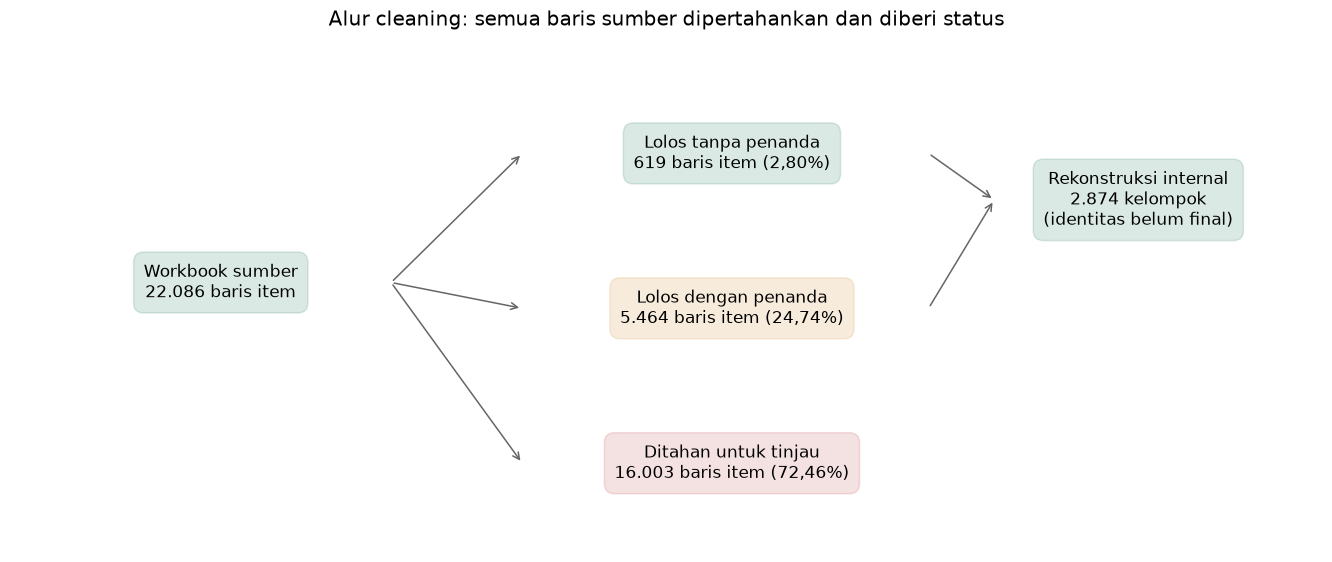

,alasan,sifat,baris_sumber_unik,kelompok_nomor_terisi,persen_seluruh_item
18,selisih_grand_total_dan_subtotal,menahan_kelompok,12543,3124,56.79
27,variasi_penulisan_nama_produk,penanda_tidak_otomatis_menahan,11438,3398,51.79
14,no_telepon_kosong,penanda_tidak_otomatis_menahan,6806,2212,30.82
0,anggota_baris_identik,penanda_tidak_otomatis_menahan,3936,582,17.82
8,kandidat_IQR_harga_satuan,penanda_tidak_otomatis_menahan,3917,2533,17.74
9,kandidat_IQR_subtotal_produk,penanda_tidak_otomatis_menahan,3722,2618,16.85
26,variasi_penulisan_nama_klien,penanda_tidak_otomatis_menahan,2826,917,12.80
24,total_tidak_dapat_direkonsiliasi,menahan_kelompok,2821,327,12.77
10,konflik_grand_total_antar_nilai_terisi,menahan_kelompok,2730,301,12.36
19,subtotal_berbeda_formula_diskon,penanda_tidak_otomatis_menahan,2722,1623,12.32


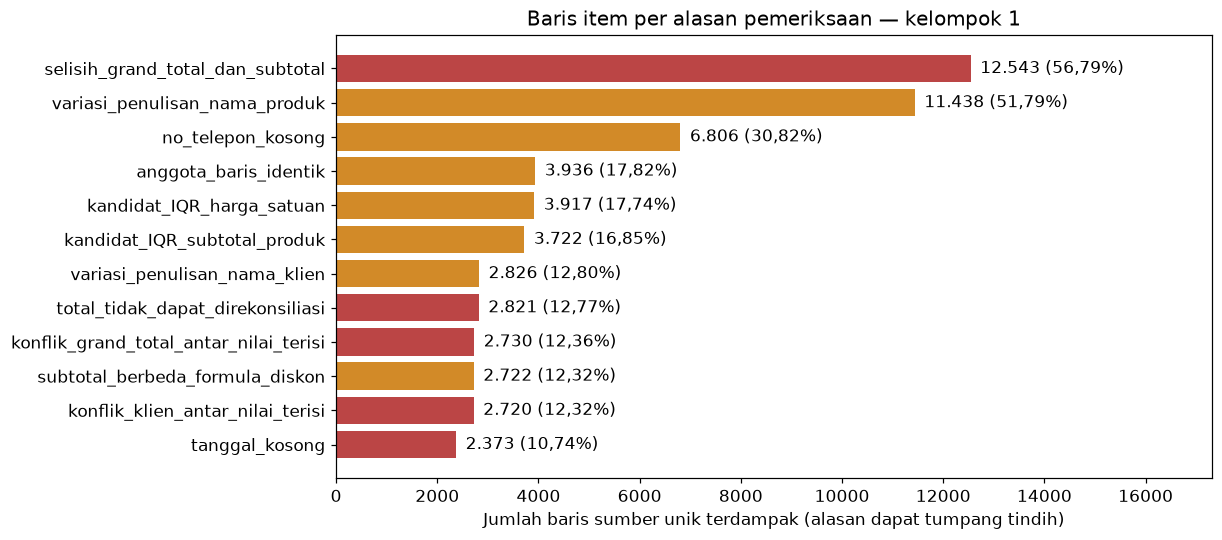

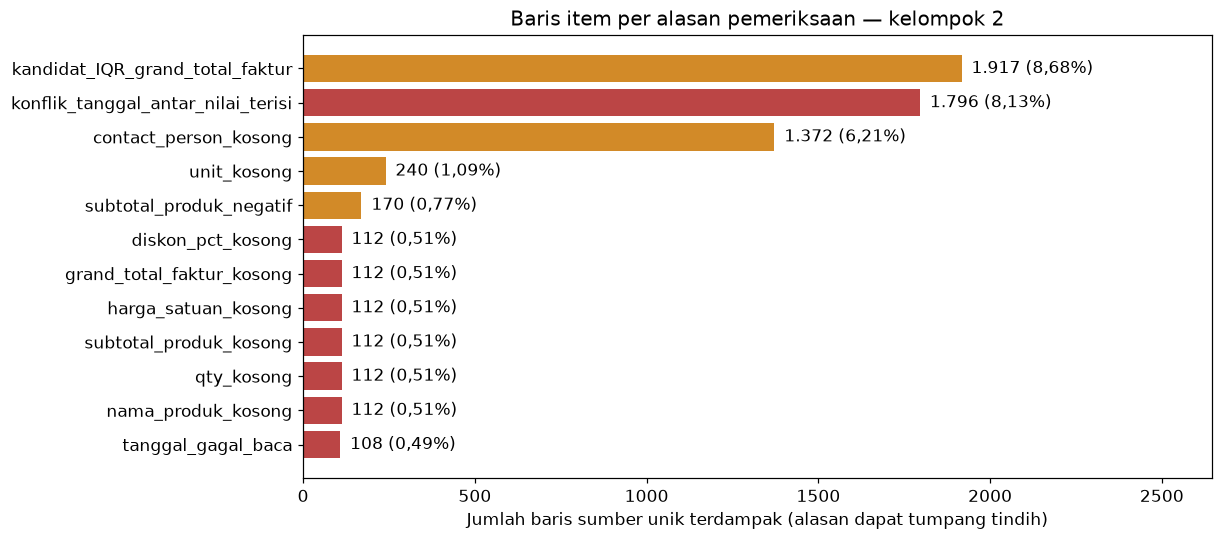

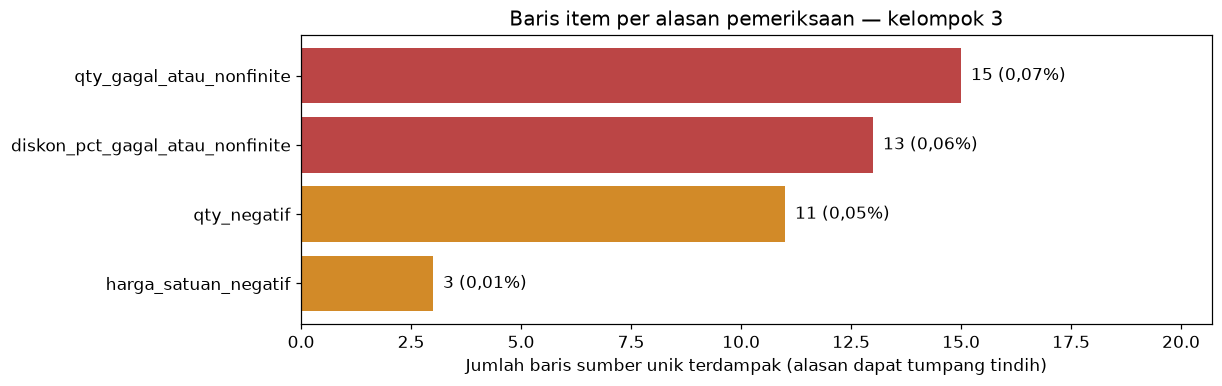

LULUS: cakupan seluruh baris, status, kelompok lolos, rekonsiliasi, IQR Tahap 1, dan integritas workbook.


In [15]:
status_counts_t2=item_audit['status_akhir'].value_counts().reindex(['lolos_internal_tanpa_penanda','lolos_internal_dengan_penanda','ditahan_untuk_tinjau'],fill_value=0)
fig,ax=plt.subplots(figsize=(12,5),layout='constrained');ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
def node_t2(x,y,text,color):
    ax.text(x,y,text,ha='center',va='center',bbox={'boxstyle':'round,pad=0.6','facecolor':color,'alpha':.16,'edgecolor':color},fontsize=11)
node_t2(.16,.52,f'Workbook sumber\n{angka(len(raw_t2))} baris item',GOOD)
node_t2(.55,.77,f'Lolos tanpa penanda\n{angka(status_counts_t2.iloc[0])} baris item ({pct(status_counts_t2.iloc[0])})',GOOD)
node_t2(.55,.47,f'Lolos dengan penanda\n{angka(status_counts_t2.iloc[1])} baris item ({pct(status_counts_t2.iloc[1])})',EMPTY)
node_t2(.55,.17,f'Ditahan untuk tinjau\n{angka(status_counts_t2.iloc[2])} baris item ({pct(status_counts_t2.iloc[2])})',CONFLICT)
node_t2(.86,.68,f'Rekonstruksi internal\n{angka(len(faktur_lolos))} kelompok\n(identitas belum final)',GOOD)
for y in [.77,.47,.17]: ax.annotate('',xy=(.39,y),xytext=(.29,.52),arrowprops={'arrowstyle':'->','color':'#666666'})
for y in [.77,.47]: ax.annotate('',xy=(.75,.68),xytext=(.70,y),arrowprops={'arrowstyle':'->','color':'#666666'})
ax.set_title('Alur cleaning: semua baris sumber dipertahankan dan diberi status')
finish(fig)
alasan_summary=kasus_tinjau.groupby(['alasan','sifat']).agg(baris_sumber_unik=('source_excel_row','nunique'),kelompok_nomor_terisi=('kelompok_kandidat','nunique')).reset_index()
alasan_summary['persen_seluruh_item']=100*alasan_summary['baris_sumber_unik']/len(raw_t2)
alasan_summary=alasan_summary.sort_values('baris_sumber_unik',ascending=False)
display(alasan_summary.round(2))
for start in range(0,len(alasan_summary),12):
    panel=alasan_summary.iloc[start:start+12]
    bars(panel.set_index('alasan')['baris_sumber_unik'],f'Baris item per alasan pemeriksaan — kelompok {start//12+1}', 'Jumlah baris sumber unik terdampak (alasan dapat tumpang tindih)',len(raw_t2),[CONFLICT if r in blocking_t2 else EMPTY for r in panel.alasan])
# Invariants check coverage, no hidden row deletion, totals and source preservation.
assert len(item_audit)==len(raw_t2) and item_audit['source_excel_row'].is_unique
assert item_audit['status_akhir'].notna().all() and status_counts_t2.sum()==len(raw_t2)
assert len(item_lolos)+int(item_audit['ditahan'].sum())==len(raw_t2)
assert faktur_lolos.index.is_unique and len(faktur_lolos)==item_lolos['kelompok_kandidat'].nunique()
assert sum(faktur_lolos['jumlah_item'])==len(item_lolos)
assert faktur_lolos['sesuai_total'].all()
assert not set(faktur_lolos.index)&blocked_groups
assert all(len(rows)==len(set(rows)) for rows in faktur_lolos['source_excel_rows'])
assert not item_audit['tanggal_dipulihkan'].any()
assert raw_t2.equals(df_raw) and item_audit[raw_t2.columns].equals(raw_t2)
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash_t2
assert set(item_audit.loc[item_audit['ditahan'],'source_excel_row']) <= set(kasus_tinjau['source_excel_row'])
for col in money_cols:
    assert int(flags_t2['kandidat_IQR_'+col].sum())==int(iqr_table.loc[col,'kandidat_baris'])
print('LULUS: cakupan seluruh baris, status, kelompok lolos, rekonsiliasi, IQR Tahap 1, dan integritas workbook.')


## Keputusan Tahap 2 dan konfirmasi yang masih diperlukan
Hasil lolos internal belum boleh dianggap sebagai identitas faktur/pelanggan final. Pemilik data perlu menyediakan ID faktur/pelanggan yang stabil atau bukti keunikan nomor lintas cabang/seri/periode, serta memvalidasi kelompok konflik. Tanggal kosong tidak diisi karena belum ada bukti identitas faktur independen.

Selisih grand total terhadap subtotal ditahan, bukan diseimbangkan dengan nilai tebakan. Minta definisi subtotal dan grand total, aturan diskon/pajak/biaya/pembulatan, kelengkapan item, serta dokumen retur atau koreksi; cek ulang item identik, negatif dan kandidat IQR. Kandidat IQR dapat mencakup transaksi sah dan tidak menjadi alasan penghapusan otomatis. Penerimaan toleransi Rp0,01 serta penanda yang tidak menahan juga perlu disepakati sebelum penggunaan bisnis.

Ketiga tabel mempertahankan penanda, sedangkan `item_audit` menyimpan setiap status akhir dan referensi sumber. Tidak ada ekspor data pelanggan, penghitungan RFM, atau pelatihan GMM pada tahap ini.


In [16]:
note(f"**Hasil akhir:** {angka(len(raw_t2))} baris sumber terbagi menjadi {angka(len(item_lolos))} item lolos internal ({pct(len(item_lolos))}) dan {angka(item_audit['ditahan'].sum())} item ditahan ({pct(item_audit['ditahan'].sum())}). Item lolos membentuk {angka(len(faktur_lolos))} kelompok kandidat faktur; {angka((faktur_lolos['status_akhir']=='lolos_internal_dengan_penanda').sum())} di antaranya tetap memiliki penanda pemeriksaan. Tanggal dipulihkan: {angka(item_audit['tanggal_dipulihkan'].sum())}; tidak ada baris sumber dihapus.")


**Hasil akhir:** 22.086 baris sumber terbagi menjadi 6.083 item lolos internal (27,54%) dan 16.003 item ditahan (72,46%). Item lolos membentuk 2.874 kelompok kandidat faktur; 2.297 di antaranya tetap memiliki penanda pemeriksaan. Tanggal dipulihkan: 0; tidak ada baris sumber dihapus.

# Tahap 2B — Audit Dampak Cleaning dan Uji Sensitivitas
Bagian ini mengaudit **cakupan kelompok kandidat**, bukan mengesahkan faktur atau pelanggan. Tabel dan status Tahap 2 tidak diubah; skenario toleransi hanya simulasi pada salinan. Satu kelompok kandidat adalah pengelompokan nomor faktur asli Tahap 2, belum satu faktur bisnis yang terverifikasi.

## 2B.1 Penyebab penahanan dan cakupan terdampak
Alasan penahanan bisa tumpang tindih: jumlah antaralasan tidak boleh dijumlahkan. “Baris terdampak” mencakup seluruh item dalam kelompok yang ditahan karena alasan tersebut, sedangkan “baris masalah langsung” hanya menghitung baris yang flag-nya aktif. Penanda nonpenahanan (identik, negatif, IQR, dan lainnya) tidak diubah menjadi alasan penahanan baru.


,metrik,hasil_hitung,angka_awal_verifikasi,sesuai
0,Baris sumber,22086,22086,True
1,Item lolos internal,6083,6083,True
2,Item ditahan,16003,16003,True
3,Kelompok kandidat lolos internal,2874,2874,True


,alasan,kelompok_ditahan,baris_item_terdampak,baris_masalah_langsung,baris_tanpa_kelompok_terdampak
15,selisih_grand_total_dan_subtotal,3124,12543,12543,0
21,tanggal_kosong,761,2373,1969,0
8,konflik_klien_antar_nilai_terisi,349,2720,2720,0
23,total_tidak_dapat_direkonsiliasi,327,2821,2821,0
7,konflik_grand_total_antar_nilai_terisi,301,2730,2730,0
9,konflik_tanggal_antar_nilai_terisi,221,1796,1796,0
4,grand_total_faktur_kosong,27,112,92,0
2,diskon_pct_kosong,27,112,92,0
6,harga_satuan_kosong,27,112,92,0
17,subtotal_produk_kosong,27,112,92,0


**Cakupan:** 6.665 kelompok kandidat dan 0 baris tanpa kelompok. Grafik berfokus pada kelompok bernomor; baris tanpa kelompok dilaporkan terpisah, bukan dianggap faktur baru.

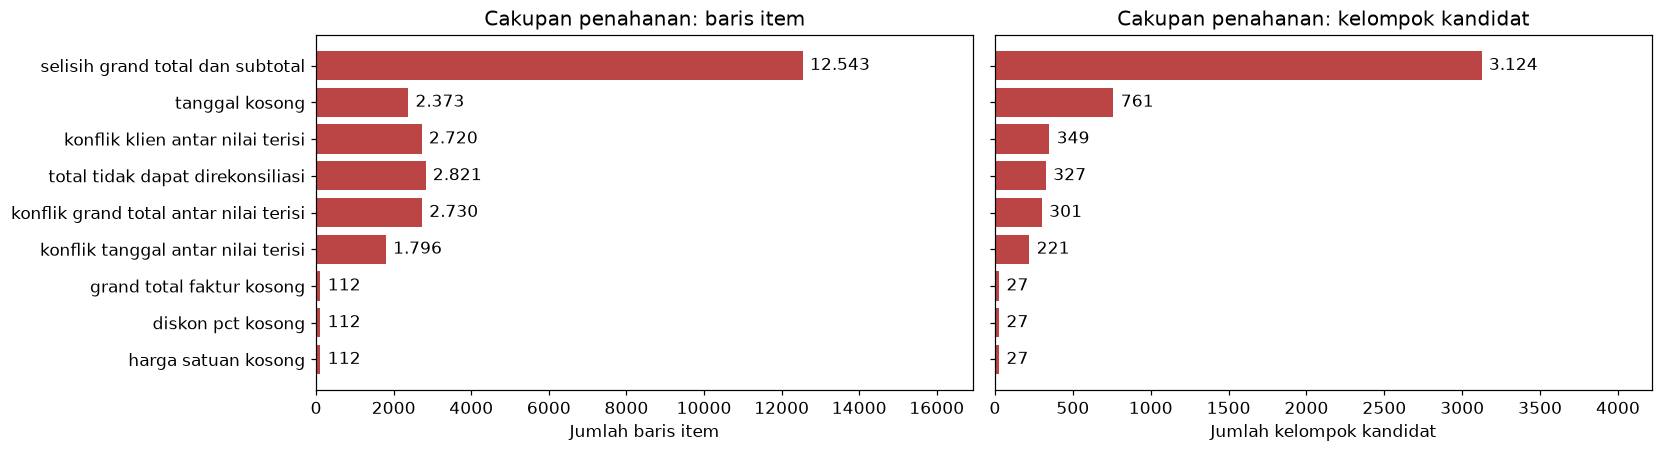

**Interpretasi:** pada panel ini, selisih grand total dan subtotal berdampak pada 12.543 baris item dalam 3.124 kelompok kandidat. Cakupan antaralasan dapat tumpang tindih dan tidak membuktikan penyebab bisnisnya.

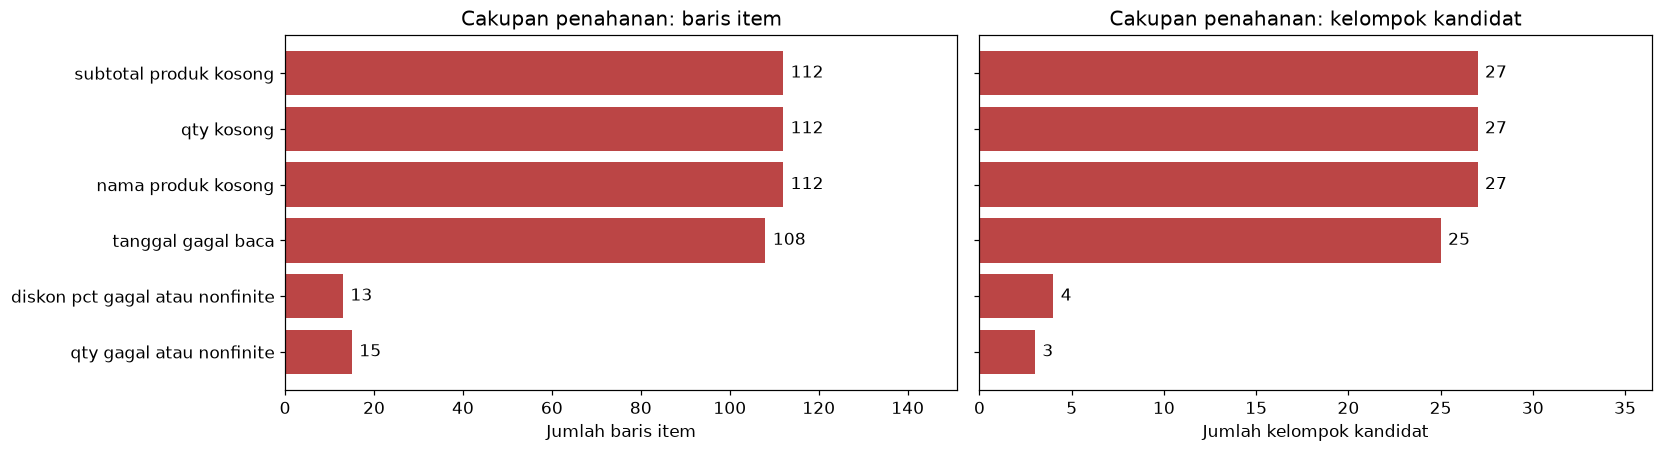

**Interpretasi:** pada panel ini, subtotal produk kosong berdampak pada 112 baris item dalam 27 kelompok kandidat. Cakupan antaralasan dapat tumpang tindih dan tidak membuktikan penyebab bisnisnya.

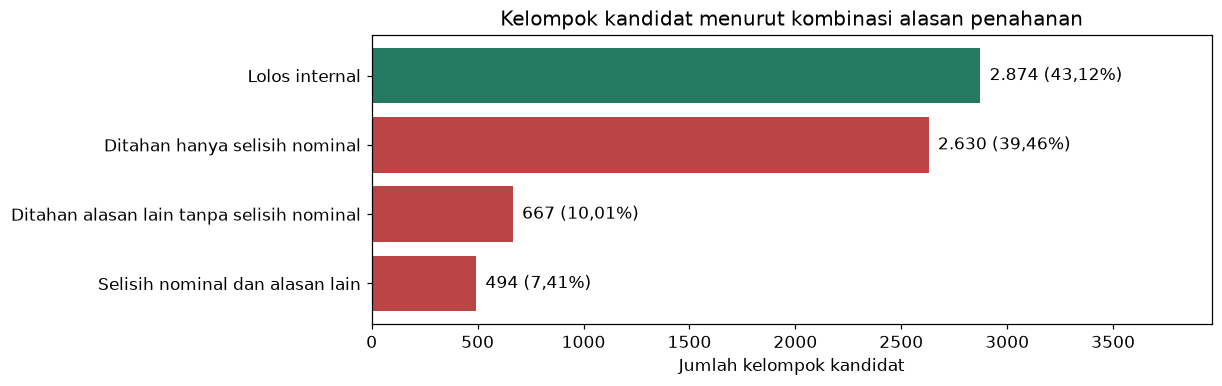

**Interpretasi:** 2.630 kelompok tertahan hanya karena selisih nominal; hanya kelompok ini yang berpotensi bertambah jika toleransi dilonggarkan. Kelompok dengan alasan lain tetap ditahan dalam seluruh simulasi, sehingga perubahan toleransi tidak menyelesaikan konflik identitas atau tanggal.

,kelompok,baris_item
kelas_penahanan,,
Ditahan alasan lain tanpa selisih nominal,667,3460
Ditahan hanya selisih nominal,2630,10503
Lolos internal,2874,6083
Selisih nominal dan alasan lain,494,2040


In [17]:
from IPython.display import HTML
# Keep full snapshots; all subsequent computations use independent copies.
snapshot_2b={name:globals()[name].copy(deep=True) for name in
             ['item_audit','item_lolos','faktur_lolos','kasus_tinjau','rekonstruksi_kandidat']}
flags_snapshot_2b=pd.DataFrame(flags_t2).copy(deep=True)
blocking_snapshot_2b=set(blocking_t2)
items_2b=item_audit.copy(deep=True)
groups_2b=rekonstruksi_kandidat.copy(deep=True)
flags_2b=flags_snapshot_2b.copy(deep=True)
N_2b=len(items_2b); G_2b=len(groups_2b)
verification_2b=pd.DataFrame({'metrik':['Baris sumber','Item lolos internal','Item ditahan','Kelompok kandidat lolos internal'],
    'hasil_hitung':[N_2b,len(item_lolos),int(items_2b['ditahan'].sum()),len(faktur_lolos)],
    'angka_awal_verifikasi':[22086,6083,16003,2874]})
verification_2b['sesuai']=verification_2b.hasil_hitung.eq(verification_2b.angka_awal_verifikasi)
display(verification_2b)
assert verification_2b['sesuai'].all(), 'Hasil Tahap 2 berubah dari angka awal; hentikan interpretasi.'
assert groups_2b.index.is_unique
valid_group_2b=items_2b['kelompok_kandidat'].notna()
no_group_2b=int((~valid_group_2b).sum())
block_group_2b=flags_2b.loc[valid_group_2b,sorted(blocking_snapshot_2b)].groupby(items_2b.loc[valid_group_2b,'kelompok_kandidat']).any().reindex(groups_2b.index,fill_value=False)
groups_2b['ditahan_dasar']=block_group_2b.any(axis=1)
assert set(groups_2b.index[~groups_2b.ditahan_dasar])==set(faktur_lolos.index)
reason_rows_2b=[]
for reason in block_group_2b:
    affected=block_group_2b[reason]
    reason_rows_2b.append({'alasan':reason,'kelompok_ditahan':int(affected.sum()),
        'baris_item_terdampak':int(groups_2b.loc[affected,'jumlah_item'].sum()),
        'baris_masalah_langsung':int(flags_2b[reason].sum()),
        'baris_tanpa_kelompok_terdampak':int((flags_2b[reason]&~valid_group_2b).sum())})
reason_audit_2b=pd.DataFrame(reason_rows_2b).sort_values('kelompok_ditahan',ascending=False)
# Independently reconcile group-level impacts with the existing review ledger.
ledger_blocks_2b=kasus_tinjau.copy(deep=True).loc[lambda t:t['sifat'].eq('menahan_kelompok')]
ledger_counts_2b=ledger_blocks_2b.groupby('alasan').agg(baris=('source_excel_row','nunique'),kelompok=('kelompok_kandidat','nunique'))
for row in reason_audit_2b.itertuples():
    ledger_row=ledger_counts_2b.reindex([row.alasan],fill_value=0).iloc[0]
    assert ledger_row['kelompok']==row.kelompok_ditahan
    assert ledger_row['baris']==row.baris_item_terdampak+row.baris_tanpa_kelompok_terdampak
display(reason_audit_2b)
note(f'**Cakupan:** {angka(G_2b)} kelompok kandidat dan {angka(no_group_2b)} baris tanpa kelompok. Grafik berfokus pada kelompok bernomor; baris tanpa kelompok dilaporkan terpisah, bukan dianggap faktur baru.')
nonzero_reasons_2b=reason_audit_2b.loc[reason_audit_2b.kelompok_ditahan.gt(0)]
for start in range(0,len(nonzero_reasons_2b),9):
    panel=nonzero_reasons_2b.iloc[start:start+9]
    fig,axes=plt.subplots(1,2,figsize=(15,max(4,len(panel)*.43)),layout='constrained')
    labels=panel.alasan.str.replace('_',' ')
    for ax,col,unit in zip(axes,['baris_item_terdampak','kelompok_ditahan'],['baris item','kelompok kandidat']):
        vals=panel[col].to_numpy(); limit=max(vals.max(),1)
        ax.barh(range(len(panel)),vals,color=CONFLICT)
        ax.set_yticks(range(len(panel)),labels if ax is axes[0] else ['']*len(panel));ax.invert_yaxis()
        ax.set_xlim(0,limit*1.35);ax.set_xlabel('Jumlah '+unit)
        ax.set_title('Cakupan penahanan: '+unit)
        for j,v in enumerate(vals):ax.text(v+limit*.015,j,angka(v),va='center')
    finish(fig)
    top=panel.iloc[0]
    note(f"**Interpretasi:** pada panel ini, {top.alasan.replace('_',' ')} berdampak pada {angka(top.baris_item_terdampak)} baris item dalam {angka(top.kelompok_ditahan)} kelompok kandidat. Cakupan antaralasan dapat tumpang tindih dan tidak membuktikan penyebab bisnisnya.")
nominal_reason_2b='selisih_grand_total_dan_subtotal'
other_blocks_2b=block_group_2b.drop(columns=nominal_reason_2b).any(axis=1)
nominal_block_2b=block_group_2b[nominal_reason_2b]
groups_2b['kelas_penahanan']=np.select([
    ~groups_2b.ditahan_dasar,nominal_block_2b & ~other_blocks_2b,nominal_block_2b & other_blocks_2b],
    ['Lolos internal','Ditahan hanya selisih nominal','Selisih nominal dan alasan lain'],default='Ditahan alasan lain tanpa selisih nominal')
classes_2b=groups_2b.groupby('kelas_penahanan').agg(kelompok=('jumlah_item','size'),baris_item=('jumlah_item','sum'))
class_plot_2b=classes_2b['kelompok'].sort_values(ascending=False)
bars(class_plot_2b,'Kelompok kandidat menurut kombinasi alasan penahanan','Jumlah kelompok kandidat',G_2b,[GOOD if label=='Lolos internal' else CONFLICT for label in class_plot_2b.index])
only_nominal_2b=int((nominal_block_2b & ~other_blocks_2b).sum())
note(f'**Interpretasi:** {angka(only_nominal_2b)} kelompok tertahan hanya karena selisih nominal; hanya kelompok ini yang berpotensi bertambah jika toleransi dilonggarkan. Kelompok dengan alasan lain tetap ditahan dalam seluruh simulasi, sehingga perubahan toleransi tidak menyelesaikan konflik identitas atau tanggal.')
display(classes_2b)


## 2B.2 Besar dan arah selisih nominal
Selisih bertanda = grand total konsisten − jumlah subtotal item; selisih absolut = nilai absolut selisih. Selisih relatif bertanda = selisih ÷ |grand total| × 100%, sedangkan selisih relatif absolut memakai |selisih|; grand total nol tidak mendapat rasio. Kelompok belum dapat direkonsiliasi tetap dipisahkan dan tidak diberi total tebakan.

Rentang absolut saling lepas: tepat Rp0; (Rp0, Rp0,01]; (Rp0,01, Rp1]; (Rp1, Rp100]; (Rp100, Rp1.000]; (Rp1.000, Rp100.000]; (Rp100.000, Rp1.000.000]; dan >Rp1.000.000. Batas kanan termasuk, batas kiri tidak; rentang ini deskriptif, sedangkan skenario memakai epsilon teknis Tahap 2 yang sama.


,kategori,kelompok
0,"Dapat dibandingkan, grand total bukan nol",6155
1,"Dapat dibandingkan, grand total nol",183
2,Belum dapat direkonsiliasi / nilai tidak finite,327


,kelompok
Grand total nol dan subtotal sesuai toleransi dasar,137
Grand total nol dan subtotal di luar toleransi,46


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
selisih_bertanda_Rp,"6.338,00","-582.451,32","8.186.703,14","-84.189.189,18","-450.000,00","0,00","0,00","130.134,00","1.375.000,00","6.985.409,08","400.000.000,00"
selisih_absolut_Rp,"6.338,00","1.431.305,21","8.081.612,06","0,00","0,00","0,00","1.000.000,00","3.500.000,00","7.500.000,00","17.480.819,20","400.000.000,00"
relatif_bertanda_persen,"6.155,00","-11,44","61,50","-1.000,00","-20,00","0,00","0,00","9,09","21,01","99,52","3.509,09"
relatif_absolut_persen,"6.155,00","21,92","58,59","0,00","0,00","0,02","33,33","83,49","100,00","114,23","3.509,09"


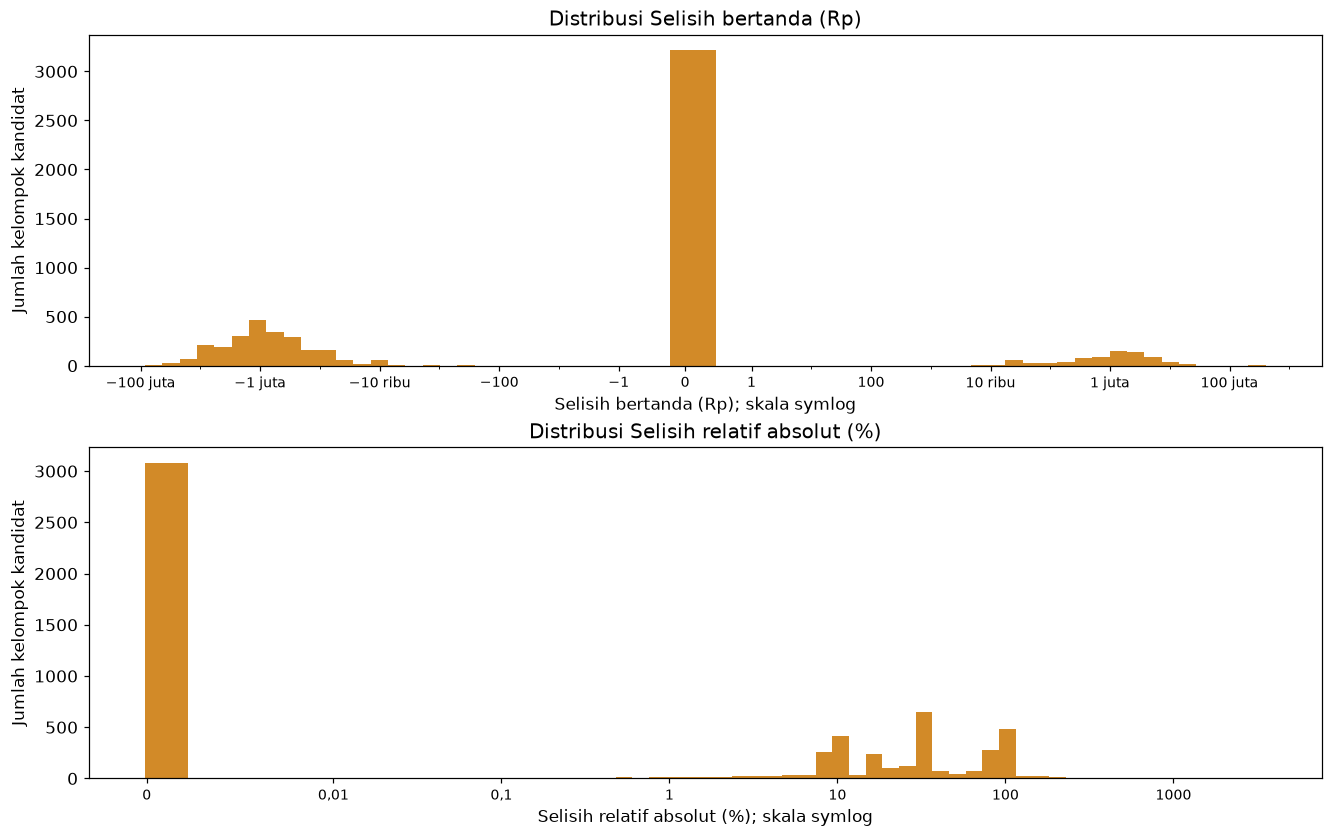

**Interpretasi:** dari 6.338 kelompok yang dapat dibandingkan, selisih positif muncul pada 751 kelompok dan negatif pada 2.373; 183 kelompok bertotal nol tidak masuk distribusi relatif. Skala symlog linear dekat nol (±Rp1 atau ±0,01%), lalu menunjukkan kelipatan nilai; arah/besar selisih ini teramati, tetapi pajak, ongkir, pembulatan, retur, atau item tidak lengkap belum terbukti sebagai penyebab.

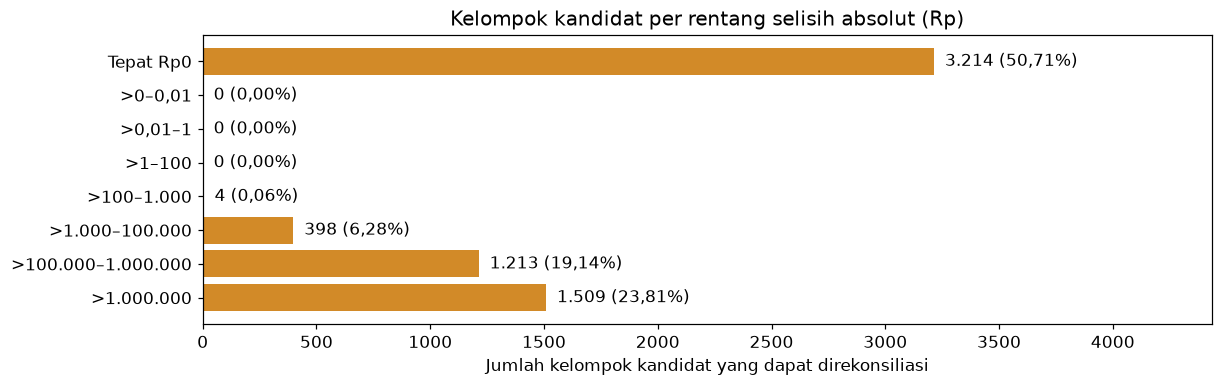

**Interpretasi:** rentang dengan kelompok terbanyak adalah Tepat Rp0, sebanyak 3.214 kelompok (50,71% dari kelompok yang dapat dibandingkan). Kelompok belum dapat direkonsiliasi berjumlah 327 dan tidak termasuk grafik maupun penyebut ini.

In [18]:
finite_recon_2b=np.isfinite(groups_2b['grand_total_konsisten_Rp']) & np.isfinite(groups_2b['subtotal_item_Rp']) & np.isfinite(groups_2b['selisih_total_Rp'])
comparable_2b=groups_2b['dapat_direkonsiliasi'] & finite_recon_2b
gaps_2b=groups_2b.loc[comparable_2b].copy()
gaps_2b['selisih_bertanda_Rp']=gaps_2b['grand_total_konsisten_Rp']-gaps_2b['subtotal_item_Rp']
gaps_2b['selisih_absolut_Rp']=gaps_2b['selisih_bertanda_Rp'].abs()
nonzero_total_2b=gaps_2b['grand_total_konsisten_Rp'].ne(0)
gaps_2b['relatif_bertanda_persen']=gaps_2b['selisih_bertanda_Rp'].div(gaps_2b['grand_total_konsisten_Rp'].abs().where(nonzero_total_2b)).mul(100)
gaps_2b['relatif_absolut_persen']=gaps_2b['relatif_bertanda_persen'].abs()
recon_coverage_2b=pd.DataFrame({'kategori':['Dapat dibandingkan, grand total bukan nol','Dapat dibandingkan, grand total nol','Belum dapat direkonsiliasi / nilai tidak finite'],
    'kelompok':[int(nonzero_total_2b.sum()),int((~nonzero_total_2b).sum()),int((~comparable_2b).sum())]})
display(recon_coverage_2b)
zero_total_audit_2b=pd.Series({'Grand total nol dan subtotal sesuai toleransi dasar':int((~nonzero_total_2b & gaps_2b.selisih_absolut_Rp.le(TOL_RP_T2+EPS_T2)).sum()),
 'Grand total nol dan subtotal di luar toleransi':int((~nonzero_total_2b & gaps_2b.selisih_absolut_Rp.gt(TOL_RP_T2+EPS_T2)).sum())},name='kelompok')
display(zero_total_audit_2b.to_frame())
summary_gaps_2b=gaps_2b[['selisih_bertanda_Rp','selisih_absolut_Rp','relatif_bertanda_persen','relatif_absolut_persen']].describe(percentiles=[.25,.5,.75,.9,.95,.99]).T
# Aggregate-only formatting avoids scientific notation in the audience table.
def show_decimal_2b(table):
    display(HTML(table.to_html(float_format=lambda v:f'{v:,.2f}'.replace(',','_').replace('.',',').replace('_','.'))))
show_decimal_2b(summary_gaps_2b)
fig,axes=plt.subplots(2,1,figsize=(12,7.5),layout='constrained')
for ax,col,unit,threshold in [(axes[0],'selisih_bertanda_Rp','Selisih bertanda (Rp)',1),(axes[1],'relatif_absolut_persen','Selisih relatif absolut (%)',.01)]:
    v=gaps_2b[col].dropna(); transformed=np.arcsinh(v/threshold)
    if len(v):
        edge_t=np.linspace(transformed.min()-.01,transformed.max()+.01,60)
        ax.hist(v,bins=np.sinh(edge_t)*threshold,color=EMPTY)
    ax.set_xscale('symlog',linthresh=threshold)
    ax.set(title='Distribusi '+unit,xlabel=unit+'; skala symlog',ylabel='Jumlah kelompok kandidat')
    if col=='selisih_bertanda_Rp':
        ax.set_xticks([-1e8,-1e6,-1e4,-100,-1,0,1,100,1e4,1e6,1e8])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:('−' if x<0 else '')+(f'{abs(x)/1e6:g} juta' if abs(x)>=1e6 else f'{abs(x)/1e3:g} ribu' if abs(x)>=1e3 else f'{abs(x):g}')))
    else:
        ax.set_xticks([0,.01,.1,1,10,100,1000])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x:g}'.replace('.',',')))
    ax.tick_params(axis='x',labelsize=9)
finish(fig)
note(f"**Interpretasi:** dari {angka(len(gaps_2b))} kelompok yang dapat dibandingkan, selisih positif muncul pada {angka(gaps_2b.selisih_bertanda_Rp.gt(0).sum())} kelompok dan negatif pada {angka(gaps_2b.selisih_bertanda_Rp.lt(0).sum())}; {angka((~nonzero_total_2b).sum())} kelompok bertotal nol tidak masuk distribusi relatif. Skala symlog linear dekat nol (±Rp1 atau ±0,01%), lalu menunjukkan kelipatan nilai; arah/besar selisih ini teramati, tetapi pajak, ongkir, pembulatan, retur, atau item tidak lengkap belum terbukti sebagai penyebab.")
abs_bins_2b=[-np.inf,0,.01,1,100,1000,100000,1000000,np.inf]
abs_labels_2b=['Tepat Rp0','>0–0,01','>0,01–1','>1–100','>100–1.000','>1.000–100.000','>100.000–1.000.000','>1.000.000']
gaps_2b['rentang_selisih_Rp']=pd.cut(gaps_2b.selisih_absolut_Rp,bins=abs_bins_2b,labels=abs_labels_2b,right=True)
range_gaps_2b=gaps_2b['rentang_selisih_Rp'].value_counts(sort=False)
bars(range_gaps_2b,'Kelompok kandidat per rentang selisih absolut (Rp)','Jumlah kelompok kandidat yang dapat direkonsiliasi',len(gaps_2b),EMPTY)
note(f"**Interpretasi:** rentang dengan kelompok terbanyak adalah {range_gaps_2b.idxmax()}, sebanyak {angka(range_gaps_2b.max())} kelompok ({pct(range_gaps_2b.max(),len(gaps_2b))} dari kelompok yang dapat dibandingkan). Kelompok belum dapat direkonsiliasi berjumlah {angka((~comparable_2b).sum())} dan tidak termasuk grafik maupun penyebut ini.")
assert range_gaps_2b.sum()==comparable_2b.sum()

assert gaps_2b.loc[~nonzero_total_2b,'relatif_absolut_persen'].isna().all()
assert gaps_2b.loc[nonzero_total_2b,'relatif_absolut_persen'].notna().all()
assert recon_coverage_2b.kelompok.sum()==G_2b


## 2B.3 Profil kelompok lolos dan ditahan
Periode memakai tahun agar jumlah kasus kecil tetap mudah dibaca. Tanggal kelompok hanya ditetapkan jika seluruh baris memiliki tanggal terbaca, tepat satu nilai, tidak ambigu, dan tidak berkonflik menurut flag Tahap 2; tidak ada pengisian tanggal. Nominal memakai satu grand total yang konsisten, lengkap dan finite, meskipun kelompok ditahan karena alasan lain. Kategori “Belum dapat ditetapkan” selalu disertakan. Penyebut tingkat kelulusan adalah seluruh kelompok pada kategori itu, bukan seluruh baris item.


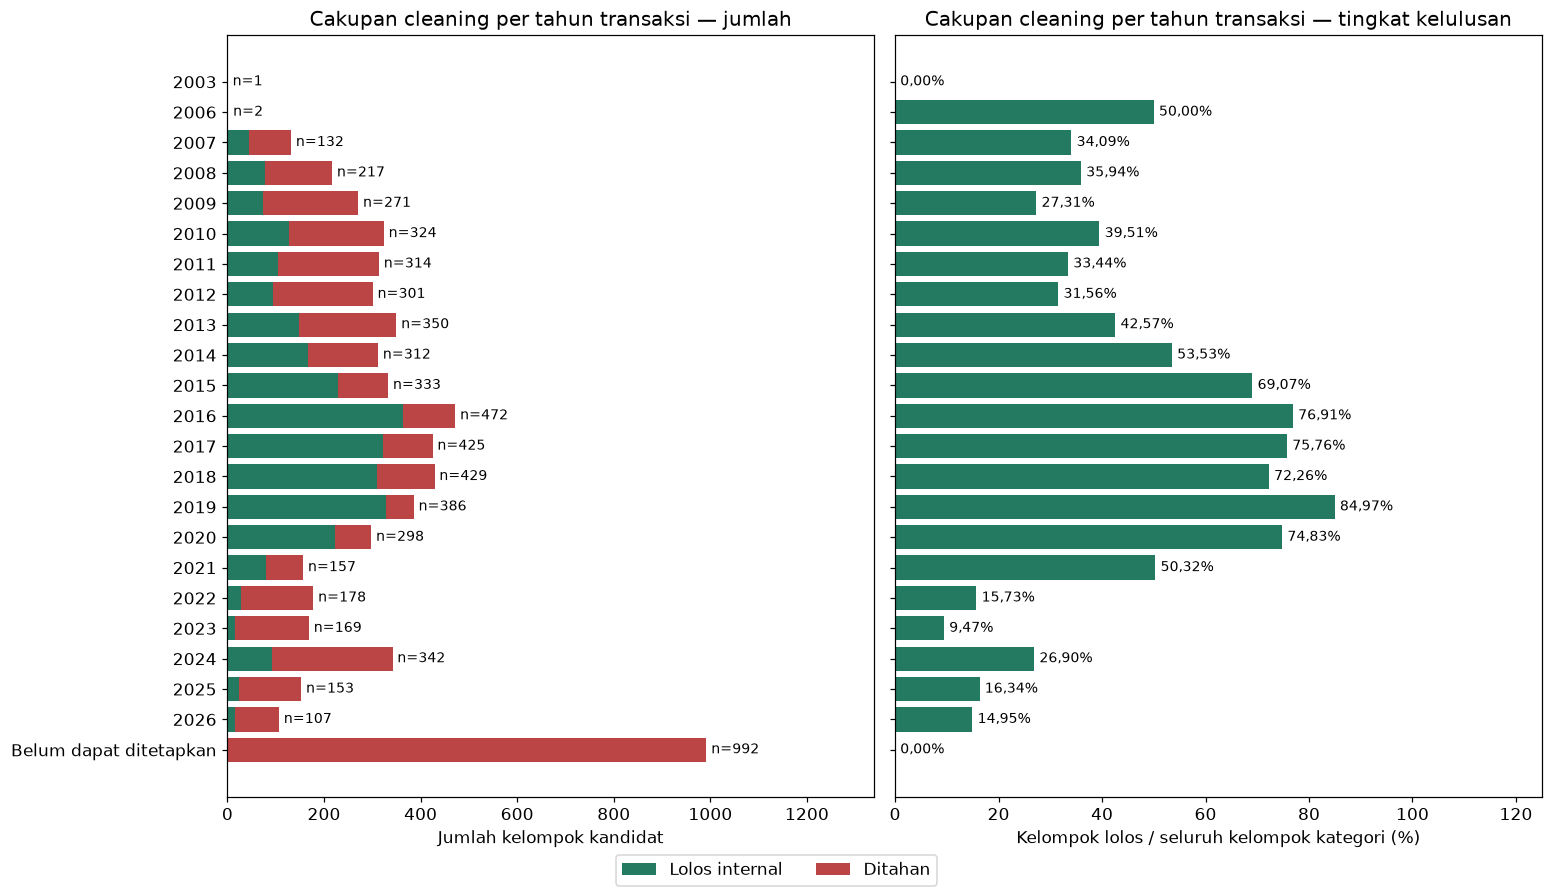

**Interpretasi:** di antara kategori diketahui berisi ≥30 kelompok (batas bantu baca, bukan uji statistik), 2023 paling sering tertahan: hanya 16 dari 169 kelompok lolos (9,47%), dibanding 2019 dengan 328 dari 386 (84,97%). Sebanyak 992 kelompok belum dapat ditetapkan kategorinya dan kategori kecil tetap ditampilkan dengan jumlahnya; perbedaan cakupan ini dapat menggeser gambaran waktu dan nilai belanja pada RFM eksploratif.

,total_kelompok,ditahan,lolos,tingkat_lolos_persen
periode,,,,
2003,1,1,0,0.00
2006,2,1,1,50.00
2007,132,87,45,34.09
2008,217,139,78,35.94
2009,271,197,74,27.31
2010,324,196,128,39.51
2011,314,209,105,33.44
2012,301,206,95,31.56
2013,350,201,149,42.57


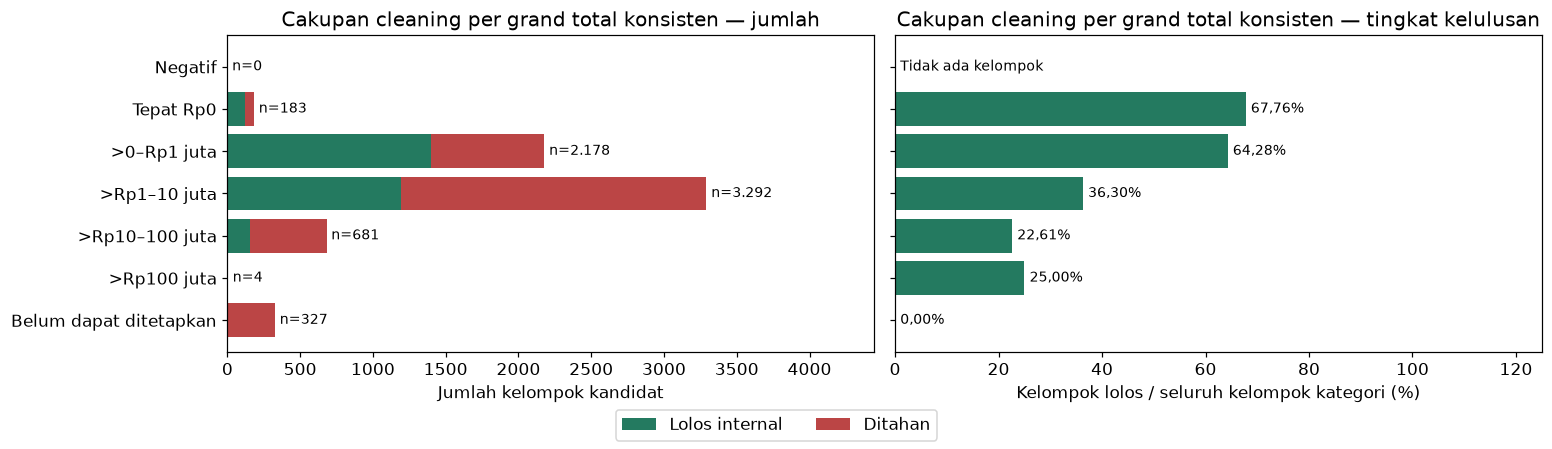

**Interpretasi:** di antara kategori diketahui berisi ≥30 kelompok (batas bantu baca, bukan uji statistik), >Rp10–100 juta paling sering tertahan: hanya 154 dari 681 kelompok lolos (22,61%), dibanding Tepat Rp0 dengan 124 dari 183 (67,76%). Sebanyak 327 kelompok belum dapat ditetapkan kategorinya dan kategori kecil tetap ditampilkan dengan jumlahnya; perbedaan cakupan ini dapat menggeser gambaran waktu dan nilai belanja pada RFM eksploratif.

,total_kelompok,ditahan,lolos,tingkat_lolos_persen
rentang_nominal,,,,
Negatif,0,0,0,NaN
Tepat Rp0,183,59,124,67.76
>0–Rp1 juta,2178,778,1400,64.28
>Rp1–10 juta,3292,2097,1195,36.30
>Rp10–100 juta,681,527,154,22.61
>Rp100 juta,4,3,1,25.00
Belum dapat ditetapkan,327,327,0,0.00


In [19]:
date_g_2b=items_2b.loc[valid_group_2b].groupby('kelompok_kandidat')
date_info_2b=date_g_2b.agg(jumlah=('source_excel_row','size'),terbaca=('tanggal_std','count'),unik=('tanggal_std','nunique'),ambigu=('tanggal_ambigu','any'),tanggal=('tanggal_std','min'))
date_ok_2b=date_info_2b.terbaca.eq(date_info_2b.jumlah)&date_info_2b.unik.eq(1)&~date_info_2b.ambigu&~block_group_2b['konflik_tanggal_antar_nilai_terisi']
groups_2b['tanggal_profil']=date_info_2b['tanggal'].where(date_ok_2b)
groups_2b['periode']=groups_2b['tanggal_profil'].dt.year.astype('Int64').astype('string').fillna('Belum dapat ditetapkan')
consistent_money_2b=groups_2b['grand_total_konsisten_Rp'].where(np.isfinite(groups_2b['grand_total_konsisten_Rp']))
money_bins_2b=[-np.inf,-np.nextafter(0,1),0,1000000,10000000,100000000,np.inf]
money_labels_2b=['Negatif','Tepat Rp0','>0–Rp1 juta','>Rp1–10 juta','>Rp10–100 juta','>Rp100 juta']
groups_2b['rentang_nominal']=pd.cut(consistent_money_2b,bins=money_bins_2b,labels=money_labels_2b).astype('string').fillna('Belum dapat ditetapkan')
def profile_2b(key,order):
    t=groups_2b.groupby(key).agg(total_kelompok=('ditahan_dasar','size'),ditahan=('ditahan_dasar','sum')).reindex(order,fill_value=0)
    t['lolos']=t.total_kelompok-t.ditahan
    t['tingkat_lolos_persen']=t.lolos.div(t.total_kelompok.where(t.total_kelompok.ne(0))).mul(100)
    return t
period_order_2b=sorted(set(groups_2b.periode)-{'Belum dapat ditetapkan'})+['Belum dapat ditetapkan']
profile_period_2b=profile_2b('periode',period_order_2b)
profile_money_2b=profile_2b('rentang_nominal',money_labels_2b+['Belum dapat ditetapkan'])
def draw_profile_2b(table,title):
    fig,axes=plt.subplots(1,2,figsize=(14,max(4,len(table)*.35)),layout='constrained',sharey=True)
    y=np.arange(len(table));limit=max(table.total_kelompok.max(),1)
    axes[0].barh(y,table.lolos,color=GOOD,label='Lolos internal')
    axes[0].barh(y,table.ditahan,left=table.lolos,color=CONFLICT,label='Ditahan')
    axes[0].set_yticks(y,table.index);axes[0].invert_yaxis();axes[0].set_xlim(0,limit*1.35)
    for j,row in enumerate(table.itertuples()):axes[0].text(row.total_kelompok+limit*.01,j,f'n={angka(row.total_kelompok)}',va='center',fontsize=9)
    axes[0].set(xlabel='Jumlah kelompok kandidat',title=title+' — jumlah')
    fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=2)
    axes[1].barh(y,table.tingkat_lolos_persen.fillna(0),color=GOOD);axes[1].set_xlim(0,125)
    for j,row in enumerate(table.itertuples()):
        axes[1].text((row.tingkat_lolos_persen if pd.notna(row.tingkat_lolos_persen) else 0)+1,j,pct(row.lolos,row.total_kelompok) if row.total_kelompok else 'Tidak ada kelompok',va='center',fontsize=9)
    axes[1].set(xlabel='Kelompok lolos / seluruh kelompok kategori (%)',title=title+' — tingkat kelulusan')
    finish(fig)
    # Compare known categories with enough groups to avoid selecting a one-case year.
    known=table.drop(index='Belum dapat ditetapkan',errors='ignore')
    eligible=known.loc[known.total_kelompok.ge(30)]
    if eligible.empty: eligible=known.loc[known.total_kelompok.gt(0)]
    lowest=eligible.tingkat_lolos_persen.idxmin(); highest=eligible.tingkat_lolos_persen.idxmax()
    lo=eligible.loc[lowest]; hi=eligible.loc[highest]
    unknown=table.loc['Belum dapat ditetapkan','total_kelompok'] if 'Belum dapat ditetapkan' in table.index else 0
    note(f'**Interpretasi:** di antara kategori diketahui berisi ≥30 kelompok (batas bantu baca, bukan uji statistik), {lowest} paling sering tertahan: hanya {angka(lo.lolos)} dari {angka(lo.total_kelompok)} kelompok lolos ({pct(lo.lolos,lo.total_kelompok)}), dibanding {highest} dengan {angka(hi.lolos)} dari {angka(hi.total_kelompok)} ({pct(hi.lolos,hi.total_kelompok)}). Sebanyak {angka(unknown)} kelompok belum dapat ditetapkan kategorinya dan kategori kecil tetap ditampilkan dengan jumlahnya; perbedaan cakupan ini dapat menggeser gambaran waktu dan nilai belanja pada RFM eksploratif.')
    display(table.round(2))
draw_profile_2b(profile_period_2b,'Cakupan cleaning per tahun transaksi')
draw_profile_2b(profile_money_2b,'Cakupan cleaning per grand total konsisten')
assert profile_period_2b.total_kelompok.sum()==G_2b
assert profile_money_2b.total_kelompok.sum()==G_2b


## 2B.4 Uji sensitivitas toleransi nominal
Rp0,01 adalah skenario dasar. Rp1, Rp100, dan Rp1.000 hanya pembanding sensitivitas, **bukan toleransi bisnis yang disetujui**. Simulasi mengganti hanya flag `selisih_grand_total_dan_subtotal`; seluruh alasan penahanan lain, termasuk kelompok belum dapat direkonsiliasi, tetap berlaku. Epsilon Rp0,000001 dari Tahap 2 dipertahankan di setiap skenario; flag diagnostik formula item dan IQR tidak dihitung ulang atau dilonggarkan.


,toleransi_Rp,kelompok_lolos,item_lolos,cakupan_kelompok_persen,tambahan_vs_dasar,perubahan_cakupan_poin_persen
0,"0,01",2874,6083,"43,12",0,"0,00"
1,"1,00",2874,6083,"43,12",0,"0,00"
2,"100,00",2874,6083,"43,12",0,"0,00"
3,"1.000,00",2877,6089,"43,17",3,"0,05"


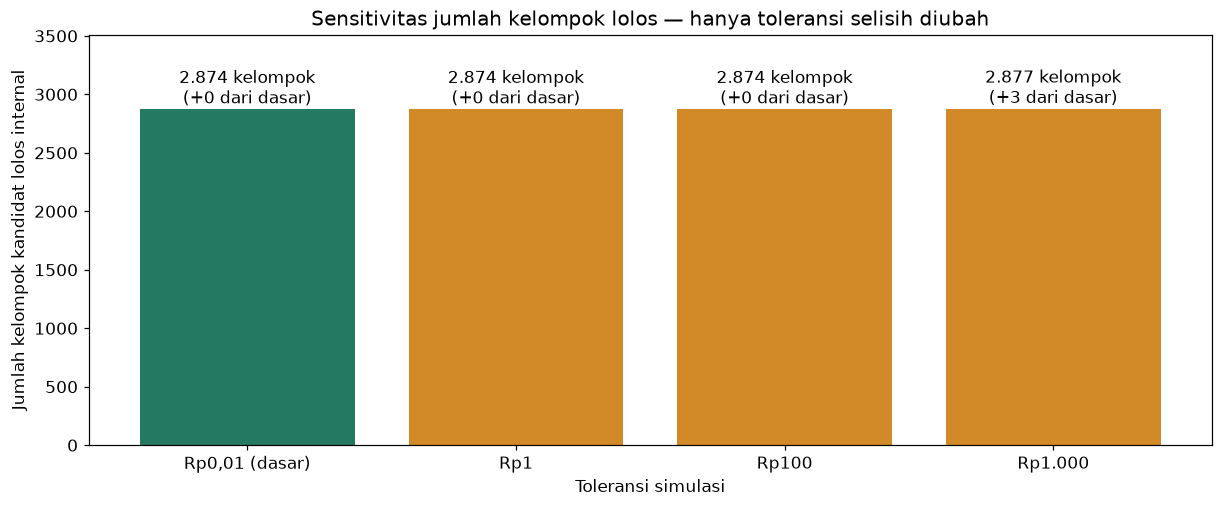

**Interpretasi:** menaikkan toleransi dari Rp0,01 menjadi Rp1.000 menambah 3 kelompok, dari 2.874 menjadi 2.877. Tambahan ini hanya perubahan cakupan aturan nominal dan tidak mengesahkan identitas, penanda pemeriksaan, atau keabsahan transaksi.

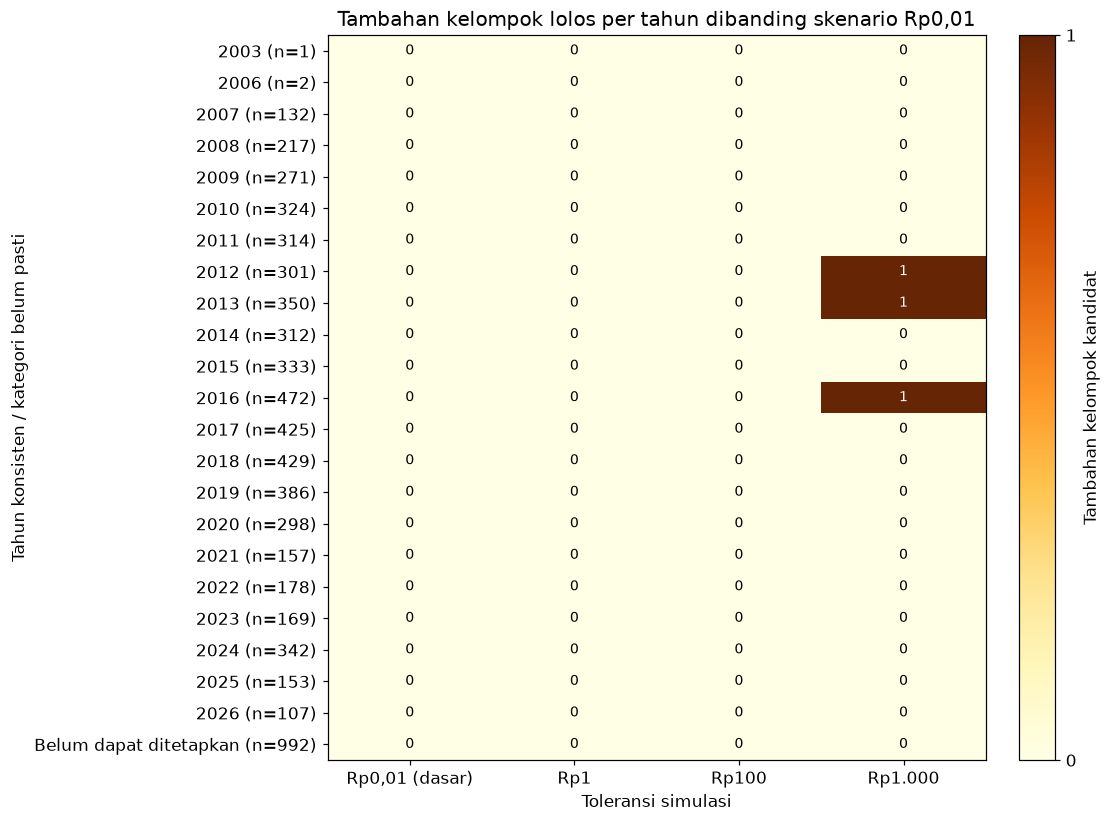

**Interpretasi:** perubahan pada skenario Rp1.000 adalah 2012: +1 kelompok dari 301; 2013: +1 kelompok dari 350; 2016: +1 kelompok dari 472. Tabel berikut memuat jumlah lolos setiap skenario dan perubahan poin persentase dengan penyebut periode tetap, sehingga kenaikan cakupan tidak tercampur perubahan jumlah kelompok sumber.

,Total kelompok,"Lolos Rp0,01",Lolos Rp1,Lolos Rp100,Lolos Rp1.000
periode,,,,,
2003,1,0,0,0,0
2006,2,1,1,1,1
2007,132,45,45,45,45
2008,217,78,78,78,78
2009,271,74,74,74,74
2010,324,128,128,128,128
2011,314,105,105,105,105
2012,301,95,95,95,96
2013,350,149,149,149,150


,Cakupan dasar (%),Delta pp Rp1,Delta pp Rp100,Delta pp Rp1.000,Cakupan Rp1.000 (%)
periode,,,,,
2003,"0,00","0,00","0,00","0,00","0,00"
2006,"50,00","0,00","0,00","0,00","50,00"
2007,"34,09","0,00","0,00","0,00","34,09"
2008,"35,94","0,00","0,00","0,00","35,94"
2009,"27,31","0,00","0,00","0,00","27,31"
2010,"39,51","0,00","0,00","0,00","39,51"
2011,"33,44","0,00","0,00","0,00","33,44"
2012,"31,56","0,00","0,00","0,33","31,89"
2013,"42,57","0,00","0,00","0,29","42,86"


In [20]:
simulation_groups_2b=groups_2b.copy(deep=True)
simulation_items_2b=items_2b.copy(deep=True)
scenario_pass_2b={}; scenario_rows_2b=[]; scenario_period_rows_2b=[]
for tol in [.01,1.,100.,1000.]:
    nominal_reject=simulation_groups_2b['dapat_direkonsiliasi'] & simulation_groups_2b['selisih_total_Rp'].abs().gt(tol+EPS_T2)
    passed=~(other_blocks_2b|nominal_reject)
    scenario_pass_2b[tol]=passed.copy()
    # Rows without a candidate group keep their original held status.
    item_pass=simulation_items_2b['kelompok_kandidat'].map(passed).fillna(False).astype(bool)
    scenario_rows_2b.append({'toleransi_Rp':tol,'kelompok_lolos':int(passed.sum()),'item_lolos':int(item_pass.sum()),'cakupan_kelompok_persen':100*passed.sum()/G_2b})
    for period in period_order_2b:
        mask=simulation_groups_2b.periode.eq(period)
        scenario_period_rows_2b.append({'toleransi_Rp':tol,'periode':period,'total_kelompok':int(mask.sum()),'kelompok_lolos':int((passed&mask).sum())})
sensitivity_2b=pd.DataFrame(scenario_rows_2b)
base_pass_2b=scenario_pass_2b[.01]
sensitivity_2b['tambahan_vs_dasar']=sensitivity_2b.kelompok_lolos-int(base_pass_2b.sum())
sensitivity_2b['perubahan_cakupan_poin_persen']=sensitivity_2b.cakupan_kelompok_persen-sensitivity_2b.cakupan_kelompok_persen.iloc[0]
assert base_pass_2b.equals(~groups_2b['ditahan_dasar'])
assert set(base_pass_2b.index[base_pass_2b])==set(faktur_lolos.index)
assert int(sensitivity_2b.iloc[0].item_lolos)==len(item_lolos)
assert simulation_items_2b.kelompok_kandidat.map(base_pass_2b).fillna(False).astype(bool).equals((~items_2b.ditahan).astype(bool))
for tol,passed in scenario_pass_2b.items():
    assert not (passed & other_blocks_2b).any()
    assert not (passed & ~simulation_groups_2b.dapat_direkonsiliasi).any()
    assert not (base_pass_2b & ~passed).any()
    assert not ((passed & ~base_pass_2b) & ~nominal_block_2b).any()
    assert (passed.sum()-base_pass_2b.sum())<=only_nominal_2b
show_decimal_2b(sensitivity_2b)
fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
values=sensitivity_2b.kelompok_lolos.to_numpy(); labels=['Rp0,01 (dasar)','Rp1','Rp100','Rp1.000']
ax.bar(labels,values,color=[GOOD,EMPTY,EMPTY,EMPTY]);ax.set_ylim(0,max(values)*1.22)
for j,row in enumerate(sensitivity_2b.itertuples()): ax.text(j,row.kelompok_lolos,f'{angka(row.kelompok_lolos)} kelompok\n(+{angka(row.tambahan_vs_dasar)} dari dasar)',ha='center',va='bottom')
ax.set(title='Sensitivitas jumlah kelompok lolos — hanya toleransi selisih diubah',xlabel='Toleransi simulasi',ylabel='Jumlah kelompok kandidat lolos internal')
finish(fig)
max_added_2b=int(sensitivity_2b.iloc[-1].tambahan_vs_dasar)
note(f'**Interpretasi:** menaikkan toleransi dari Rp0,01 menjadi Rp1.000 menambah {angka(max_added_2b)} kelompok, dari {angka(base_pass_2b.sum())} menjadi {angka(scenario_pass_2b[1000.].sum())}. Tambahan ini hanya perubahan cakupan aturan nominal dan tidak mengesahkan identitas, penanda pemeriksaan, atau keabsahan transaksi.')
sensitivity_period_2b=pd.DataFrame(scenario_period_rows_2b)
base_by_period_2b=sensitivity_period_2b.loc[sensitivity_period_2b.toleransi_Rp.eq(.01)].set_index('periode').kelompok_lolos
sensitivity_period_2b['tambahan_vs_dasar']=sensitivity_period_2b.kelompok_lolos-sensitivity_period_2b.periode.map(base_by_period_2b)
sensitivity_period_2b['cakupan_persen']=100*sensitivity_period_2b.kelompok_lolos/sensitivity_period_2b.total_kelompok.replace(0,np.nan)
sensitivity_period_2b['perubahan_poin_persen']=100*sensitivity_period_2b.tambahan_vs_dasar/sensitivity_period_2b.total_kelompok.replace(0,np.nan)
# Heatmap counts show absolute change; the table below also reports percentage points.
heat_2b=sensitivity_period_2b.pivot(index='periode',columns='toleransi_Rp',values='tambahan_vs_dasar').reindex(period_order_2b)
fig,ax=plt.subplots(figsize=(10,max(4,len(heat_2b)*.32)),layout='constrained')
im=ax.imshow(heat_2b.to_numpy(),aspect='auto',cmap='YlOrBr',vmin=0,vmax=max(1,heat_2b.to_numpy().max()))
ax.set_xticks(range(4),labels);ax.set_yticks(range(len(heat_2b)),[f'{p} (n={angka(profile_period_2b.loc[p,"total_kelompok"])})' for p in heat_2b.index])
for y in range(len(heat_2b)):
    for x in range(4):ax.text(x,y,angka(heat_2b.iloc[y,x]),ha='center',va='center',fontsize=9,color='white' if heat_2b.iloc[y,x]>max(1,heat_2b.to_numpy().max())*.6 else 'black')
ax.set(title='Tambahan kelompok lolos per tahun dibanding skenario Rp0,01',xlabel='Toleransi simulasi',ylabel='Tahun konsisten / kategori belum pasti')
colorbar_2b=fig.colorbar(im,ax=ax,label='Tambahan kelompok kandidat')
colorbar_2b.set_ticks(range(int(heat_2b.to_numpy().max())+1))
finish(fig)
added_period_2b=heat_2b[1000.]
changed_periods_2b=added_period_2b[added_period_2b.gt(0)]
period_change_text_2b='; '.join(f'{p}: +{angka(v)} kelompok dari {angka(profile_period_2b.loc[p,"total_kelompok"])}' for p,v in changed_periods_2b.items()) or 'tidak ada periode dengan tambahan kelompok'
note(f'**Interpretasi:** perubahan pada skenario Rp1.000 adalah {period_change_text_2b}. Tabel berikut memuat jumlah lolos setiap skenario dan perubahan poin persentase dengan penyebut periode tetap, sehingga kenaikan cakupan tidak tercampur perubahan jumlah kelompok sumber.')
# Compact, complete tables: no hidden middle rows in the 92-row scenario audit.
period_counts_2b=sensitivity_period_2b.pivot(index='periode',columns='toleransi_Rp',values='kelompok_lolos').reindex(period_order_2b)
period_counts_2b.columns=['Lolos Rp0,01','Lolos Rp1','Lolos Rp100','Lolos Rp1.000']
period_counts_2b.insert(0,'Total kelompok',profile_period_2b.total_kelompok)
display(HTML(period_counts_2b.to_html()))
period_pp_2b=sensitivity_period_2b.pivot(index='periode',columns='toleransi_Rp',values='perubahan_poin_persen').reindex(period_order_2b).drop(columns=.01)
period_pp_2b.columns=['Delta pp Rp1','Delta pp Rp100','Delta pp Rp1.000']
period_pp_2b.insert(0,'Cakupan dasar (%)',profile_period_2b.tingkat_lolos_persen)
period_pp_2b['Cakupan Rp1.000 (%)']=period_pp_2b['Cakupan dasar (%)']+period_pp_2b['Delta pp Rp1.000']
show_decimal_2b(period_pp_2b)
for smaller,larger in zip([.01,1.,100.],[1.,100.,1000.]):
    assert not (scenario_pass_2b[smaller]&~scenario_pass_2b[larger]).any()
assert all(int(sensitivity_period_2b.loc[sensitivity_period_2b.toleransi_Rp.eq(t),'kelompok_lolos'].sum())==int(p.sum()) for t,p in scenario_pass_2b.items())


## 2B.5 Audit identitas pelanggan untuk persiapan RFM
Standardisasi nama hanya menyamakan kapital dan spasi; tidak membuktikan bahwa orang/perusahaan yang namanya sama adalah pelanggan yang sama. Telepon dapat dipakai bersama atau berubah. Audit berikut menghitung nama standar dengan beberapa ejaan asli serta telepon standar yang terkait beberapa nama standar, tanpa menampilkan nilainya dan tanpa penggabungan otomatis.


,cakupan,nama_standar_terisi,nama_dengan_beberapa_ejaan,baris_dalam_variasi_nama,telepon_standar_terisi,telepon_terkait_beberapa_nama,baris_dengan_telepon_terkait_beberapa_nama
0,Seluruh sumber,2864,110,2826,2254,201,3085
1,Subset lolos internal,1456,57,657,1194,61,576


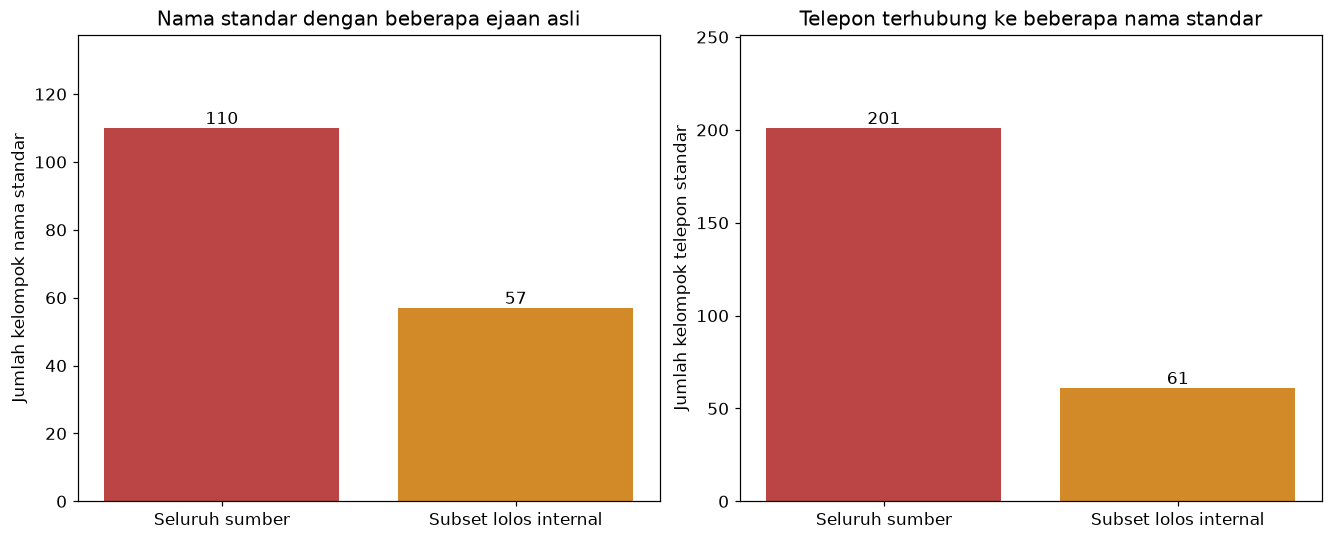

**Interpretasi:** seluruh workbook memuat 110 nama standar dengan beberapa ejaan asli dan 201 telepon yang terkait beberapa nama standar; hitungan subset pada grafik dihitung ulang di dalam subset, bukan bukti masalah telah selesai. Jika pola seluruh workbook dipakai sebagai rujukan, 857 item lolos masih terpapar variasi nama dan 895 item lolos memakai telepon terkait beberapa nama; nama standar hanya layak sebagai label pelanggan sementara yang dapat salah menggabungkan atau memisahkan pelanggan.

In [21]:
def identity_audit_2b(table,label):
    names=table.dropna(subset=['nama_klien_std']).groupby('nama_klien_std')['nama_klien'].nunique()
    phones=table.dropna(subset=['no_telepon_std']).groupby('no_telepon_std')['nama_klien_std'].nunique()
    varied=names[names.gt(1)].index; shared=phones[phones.gt(1)].index
    return {'cakupan':label,'nama_standar_terisi':len(names),'nama_dengan_beberapa_ejaan':len(varied),
        'baris_dalam_variasi_nama':int(table.nama_klien_std.isin(varied).sum()),
        'telepon_standar_terisi':len(phones),'telepon_terkait_beberapa_nama':len(shared),
        'baris_dengan_telepon_terkait_beberapa_nama':int(table.no_telepon_std.isin(shared).sum())}
identity_summary_2b=pd.DataFrame([identity_audit_2b(items_2b,'Seluruh sumber'),identity_audit_2b(item_lolos.copy(deep=True),'Subset lolos internal')])
# Also measure exposure of the passed subset to collisions identified in the full workbook.
name_variants_all_2b=items_2b.groupby('nama_klien_std')['nama_klien'].nunique()
shared_phone_all_2b=items_2b.dropna(subset=['no_telepon_std']).groupby('no_telepon_std')['nama_klien_std'].nunique()
passed_name_exposure_2b=int(item_lolos.nama_klien_std.isin(name_variants_all_2b[name_variants_all_2b.gt(1)].index).sum())
passed_phone_exposure_2b=int(item_lolos.no_telepon_std.isin(shared_phone_all_2b[shared_phone_all_2b.gt(1)].index).sum())
display(identity_summary_2b)
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,col,title,unit in [(axes[0],'nama_dengan_beberapa_ejaan','Nama standar dengan beberapa ejaan asli','kelompok nama standar'),(axes[1],'telepon_terkait_beberapa_nama','Telepon terhubung ke beberapa nama standar','kelompok telepon standar')]:
    vals=identity_summary_2b[col].to_numpy();ax.bar(identity_summary_2b.cakupan,vals,color=[CONFLICT,EMPTY]);ax.set_ylim(0,max(max(vals),1)*1.25)
    ax.set(title=title,ylabel='Jumlah '+unit)
    for j,v in enumerate(vals):ax.text(j,v,angka(v),ha='center',va='bottom')
finish(fig)
a=identity_summary_2b.iloc[0]
note(f'**Interpretasi:** seluruh workbook memuat {angka(a.nama_dengan_beberapa_ejaan)} nama standar dengan beberapa ejaan asli dan {angka(a.telepon_terkait_beberapa_nama)} telepon yang terkait beberapa nama standar; hitungan subset pada grafik dihitung ulang di dalam subset, bukan bukti masalah telah selesai. Jika pola seluruh workbook dipakai sebagai rujukan, {angka(passed_name_exposure_2b)} item lolos masih terpapar variasi nama dan {angka(passed_phone_exposure_2b)} item lolos memakai telepon terkait beberapa nama; nama standar hanya layak sebagai label pelanggan sementara yang dapat salah menggabungkan atau memisahkan pelanggan.')


## Kesiapan Menuju RFM
Subset lolos internal **dapat dipakai untuk RFM eksploratif secara bersyarat**, sebagai analisis subset kandidat dan label nama sementara, setelah batas cakupan dan penanda bisnis diakui. Hasilnya bukan segmentasi pelanggan tervalidasi dan tidak mewakili seluruh pelanggan/penjualan workbook; perubahan komposisi periode dan rentang nominal dapat menggeser Recency, Frequency, dan Monetary.

Sebelum penggunaan bisnis, konfirmasikan ID faktur dan pelanggan, keunikan nomor lintas cabang/seri/periode, format serta kelengkapan tanggal, definisi grand total/subtotal/diskon/biaya, kelengkapan item, retur, baris identik, dan toleransi nominal kepada pemilik data. Pajak/ongkir/pembulatan/retur/item hilang masih hipotesis, bukan penyebab yang dibuktikan audit ini. Skenario pembanding tidak menggantikan status Tahap 2; RFM dan GMM belum dihitung.


In [22]:
held_groups_2b=int(groups_2b.ditahan_dasar.sum())
readiness_2b=pd.DataFrame([
 ['Cakupan dasar',f'{angka(base_pass_2b.sum())} dari {angka(G_2b)} kelompok ({pct(base_pass_2b.sum(),G_2b)}) lolos; {angka(held_groups_2b)} ditahan','Subset bukan representasi otomatis seluruh workbook'],
 ['Alasan nominal',f'{angka(only_nominal_2b)} kelompok ditahan hanya karena selisih nominal; {angka((nominal_block_2b&other_blocks_2b).sum())} juga memiliki alasan lain','Pelonggaran nominal tidak menyelesaikan konflik atau atribut yang hilang'],
 ['Sensitivitas Rp1.000',f'Tambahan {angka(max_added_2b)} kelompok; cakupan {pct(scenario_pass_2b[1000.].sum(),G_2b)} dibanding {pct(base_pass_2b.sum(),G_2b)} pada dasar','Toleransi bisnis tetap menunggu konfirmasi pemilik data'],
 ['Tanggal/nominal belum pasti',f'{angka(groups_2b.tanggal_profil.isna().sum())} kelompok tanpa tanggal profil; {angka(consistent_money_2b.isna().sum())} tanpa nominal konsisten','Risiko bias waktu dan besaran belanja perlu dicatat'],
 ['Identitas pelanggan',f'{angka(a.nama_dengan_beberapa_ejaan)} kelompok variasi nama; {angka(a.telepon_terkait_beberapa_nama)} telepon terkait beberapa nama','Minta ID pelanggan; jangan gabungkan otomatis']
],columns=['temuan','bukti_terhitung','implikasi_keputusan'])
display(HTML(readiness_2b.to_html(index=False)))
for name,before in snapshot_2b.items():pd.testing.assert_frame_equal(globals()[name],before)
pd.testing.assert_frame_equal(pd.DataFrame(flags_t2),flags_snapshot_2b)
assert blocking_t2==blocking_snapshot_2b
assert raw_t2.equals(df_raw) and df_raw.equals(raw_snapshot)
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest()==source_hash_t2
assert int(sensitivity_2b.iloc[0].kelompok_lolos)==2874 and int(sensitivity_2b.iloc[0].item_lolos)==6083
assert int(items_2b.ditahan.sum())==16003 and len(items_2b)==22086
print('LULUS: angka dasar tereproduksi; lima tabel, seluruh flag, aturan penahanan dan workbook Tahap 2 tetap utuh. Audit berhenti sebelum RFM/GMM.')


temuan,bukti_terhitung,implikasi_keputusan
Cakupan dasar,"2.874 dari 6.665 kelompok (43,12%) lolos; 3.791 ditahan",Subset bukan representasi otomatis seluruh workbook
Alasan nominal,2.630 kelompok ditahan hanya karena selisih nominal; 494 juga memiliki alasan lain,Pelonggaran nominal tidak menyelesaikan konflik atau atribut yang hilang
Sensitivitas Rp1.000,"Tambahan 3 kelompok; cakupan 43,17% dibanding 43,12% pada dasar",Toleransi bisnis tetap menunggu konfirmasi pemilik data
Tanggal/nominal belum pasti,992 kelompok tanpa tanggal profil; 327 tanpa nominal konsisten,Risiko bias waktu dan besaran belanja perlu dicatat
Identitas pelanggan,110 kelompok variasi nama; 201 telepon terkait beberapa nama,Minta ID pelanggan; jangan gabungkan otomatis


LULUS: angka dasar tereproduksi; lima tabel, seluruh flag, aturan penahanan dan workbook Tahap 2 tetap utuh. Audit berhenti sebelum RFM/GMM.
